In [ ]:
# cell 1: imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                              f1_score, confusion_matrix, classification_report,
                              roc_auc_score)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from scipy import stats

print("All imports successful")

All imports successful


In [ ]:
# Cell 2 — Load NSL-KDD Dataset

# Column names for NSL-KDD (41 features + label + difficulty)
columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes',
    'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
    'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
    'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate',
    'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
    'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate', 'label', 'difficulty'
]

# Load training data
train_df = pd.read_csv('../data/KDDTrain+.txt', names=columns)

# Load test data  
test_df = pd.read_csv('../data/KDDTest+.txt', names=columns)

print(f"Training set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")
print(f"\nFirst few rows:")
train_df.head()

Training set shape: (125973, 43)
Test set shape: (22544, 43)

First few rows:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [ ]:
# Cell 3 — Explore the Dataset

print("=== LABEL DISTRIBUTION IN TRAINING SET ===")
print(train_df['label'].value_counts())

print("\n=== ATTACK TYPE COUNTS ===")
# NSL-KDD has specific attack names — group them into categories
attack_types = {
    'normal': 'normal',
    'neptune': 'DoS', 'back': 'DoS', 'land': 'DoS', 'pod': 'DoS',
    'smurf': 'DoS', 'teardrop': 'DoS', 'mailbomb': 'DoS',
    'apache2': 'DoS', 'processtable': 'DoS', 'udpstorm': 'DoS',
    'ipsweep': 'Probe', 'nmap': 'Probe', 'portsweep': 'Probe',
    'satan': 'Probe', 'mscan': 'Probe', 'saint': 'Probe',
    'ftp_write': 'R2L', 'guess_passwd': 'R2L', 'imap': 'R2L',
    'multihop': 'R2L', 'phf': 'R2L', 'spy': 'R2L', 'warezclient': 'R2L',
    'warezmaster': 'R2L', 'sendmail': 'R2L', 'named': 'R2L',
    'snmpgetattack': 'R2L', 'snmpguess': 'R2L', 'worm': 'R2L',
    'xlock': 'R2L', 'xsnoop': 'R2L', 'httptunnel': 'R2L',
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'perl': 'U2R',
    'rootkit': 'U2R', 'ps': 'U2R', 'sqlattack': 'U2R',
    'xterm': 'U2R', 'httptunnel': 'U2R'
}

train_df['attack_category'] = train_df['label'].map(
    lambda x: attack_types.get(x, 'other')
)

print(train_df['attack_category'].value_counts())

print("\n=== DATA TYPES ===")
print(train_df.dtypes.value_counts())

print("\n=== MISSING VALUES ===")
print(train_df.isnull().sum().sum(), "missing values total")

=== LABEL DISTRIBUTION IN TRAINING SET ===
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

=== ATTACK TYPE COUNTS ===
attack_category
normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

=== DATA TYPES ===
int64      24
float64    15
str         5
Name: count, dtype: int64

=== MISSING VALUES ===
0 missing values total


In [ ]:
# Cell 4 — Preprocessing

# Step 1: Convert labels to binary (normal=0, attack=1)
# This is the main classification task
train_df['binary_label'] = (train_df['label'] != 'normal').astype(int)
test_df['binary_label'] = (test_df['label'] != 'normal').astype(int)

print("Binary label distribution (training):")
print(train_df['binary_label'].value_counts())
print(f"\nAttack percentage: {train_df['binary_label'].mean()*100:.2f}%")

# Step 2: Encode categorical features
# Three features are text-based: protocol_type, service, flag
le = LabelEncoder()

categorical_features = ['protocol_type', 'service', 'flag']

for col in categorical_features:
    # Fit on combined data so both train and test have same encoding
    combined = pd.concat([train_df[col], test_df[col]])
    le.fit(combined)
    train_df[col] = le.transform(train_df[col])
    test_df[col] = le.transform(test_df[col])

print("\nCategorical features encoded successfully")

# Step 3: Select features and labels
feature_columns = [col for col in columns[:41]]  # First 41 columns are features

X_train = train_df[feature_columns].values
y_train = train_df['binary_label'].values

X_test = test_df[feature_columns].values
y_test = test_df['binary_label'].values

print(f"\nTraining features shape: {X_train.shape}")
print(f"Test features shape: {X_test.shape}")

# Step 4: Scale features
# Important for algorithms like KNN and SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # Use same scaler fitted on training data

print("\nFeature scaling complete")
print(f"Feature mean (should be ~0): {X_train_scaled.mean():.4f}")
print(f"Feature std (should be ~1): {X_train_scaled.std():.4f}")

Binary label distribution (training):
binary_label
0    67343
1    58630
Name: count, dtype: int64

Attack percentage: 46.54%

Categorical features encoded successfully

Training features shape: (125973, 41)
Test features shape: (22544, 41)

Feature scaling complete
Feature mean (should be ~0): 0.0000
Feature std (should be ~1): 0.9877


In [ ]:
# Cell 5 — Feature Selection
# Your professor's papers emphasize "simple statistical techniques in feature selection"
# This is where you implement that

from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.ensemble import RandomForestClassifier
import numpy as np

print("=== FEATURE IMPORTANCE ANALYSIS ===\n")

# Method 1: Statistical test (ANOVA F-score)
# Tests which features have statistically significant differences between classes
selector_anova = SelectKBest(f_classif, k='all')
selector_anova.fit(X_train_scaled, y_train)
anova_scores = selector_anova.scores_

# Method 2: Random Forest feature importance
# Trains a quick forest and measures which features it uses most
rf_quick = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf_quick.fit(X_train, y_train)
rf_importance = rf_quick.feature_importances_

# Create a comparison DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_columns,
    'ANOVA_Score': anova_scores,
    'RF_Importance': rf_importance
})

# Rank features
feature_importance_df['ANOVA_Rank'] = feature_importance_df['ANOVA_Score'].rank(ascending=False)
feature_importance_df['RF_Rank'] = feature_importance_df['RF_Importance'].rank(ascending=False)

print("Top 15 Features by ANOVA F-Score:")
print(feature_importance_df.nlargest(15, 'ANOVA_Score')[['Feature', 'ANOVA_Score']].to_string())

print("\nTop 15 Features by Random Forest Importance:")
print(feature_importance_df.nlargest(15, 'RF_Importance')[['Feature', 'RF_Importance']].to_string())

# Select top 20 features for use in experiments
top_features_idx = feature_importance_df.nlargest(20, 'RF_Importance').index.tolist()
top_feature_names = feature_importance_df.loc[top_features_idx, 'Feature'].tolist()
print(f"\nSelected top 20 features: {top_feature_names}")

# Create reduced feature sets
X_train_selected = X_train_scaled[:, top_features_idx]
X_test_selected = X_test_scaled[:, top_features_idx]
print(f"\nReduced feature set shape: {X_train_selected.shape}")

=== FEATURE IMPORTANCE ANALYSIS ===

Top 15 Features by ANOVA F-Score:
                     Feature    ANOVA_Score
28             same_srv_rate  163866.577207
32        dst_host_srv_count  137598.286145
33    dst_host_same_srv_rate  116917.276744
11                 logged_in  114585.761111
38  dst_host_srv_serror_rate   94646.003539
37      dst_host_serror_rate   93069.951011
24               serror_rate   92481.504759
25           srv_serror_rate   91324.684661
3                       flag   90735.955707
22                     count   62689.677518
31            dst_host_count   20620.101218
1              protocol_type   10829.172311
2                    service   10431.963207
27           srv_rerror_rate    8651.409358
40  dst_host_srv_rerror_rate    8646.026365

Top 15 Features by Random Forest Importance:
                        Feature  RF_Importance
4                     src_bytes       0.239307
5                     dst_bytes       0.105594
3                          flag       

In [ ]:
# Cell 6 — Main Experiment
# This is the core of your paper

def evaluate_model(name, model, X_train, X_test, y_train, y_test, use_scaled=True):
    """
    Train a model, measure time, and calculate all evaluation metrics.
    Returns a dictionary of results.
    """
    print(f"\nRunning: {name}")
    
    # Measure training time
    start_train = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start_train
    
    # Measure prediction time
    start_pred = time.time()
    y_pred = model.predict(X_test)
    pred_time = time.time() - start_pred
    
    # Calculate all metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    # False positive rate = FP / (FP + TN)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    
    results = {
        'Model': name,
        'Accuracy': round(accuracy * 100, 2),
        'Precision': round(precision * 100, 2),
        'Recall': round(recall * 100, 2),
        'F1_Score': round(f1 * 100, 2),
        'False_Positive_Rate': round(fpr * 100, 2),
        'Train_Time_Sec': round(train_time, 3),
        'Predict_Time_Sec': round(pred_time, 4),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    }
    
    print(f"  Accuracy:  {accuracy*100:.2f}%")
    print(f"  F1 Score:  {f1*100:.2f}%")
    print(f"  FPR:       {fpr*100:.2f}%")
    print(f"  Train time: {train_time:.3f}s")
    
    return results, model, y_pred

# Define all models you will compare
# Each is a method from your paper
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Run all experiments
all_results = []
all_predictions = {}
trained_models = {}

print("="*60)
print("RUNNING ALL EXPERIMENTS")
print("="*60)

for name, model in models.items():
    # Use scaled features for all models
    result, trained_model, y_pred = evaluate_model(
        name, model, 
        X_train_scaled, X_test_scaled,
        y_train, y_test
    )
    all_results.append(result)
    all_predictions[name] = y_pred
    trained_models[name] = trained_model

# Convert to DataFrame for easy analysis
results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values('F1_Score', ascending=False)

print("\n" + "="*60)
print("FINAL RESULTS TABLE")
print("="*60)
print(results_df[['Model', 'Accuracy', 'Precision', 'Recall', 
                   'F1_Score', 'False_Positive_Rate', 
                   'Train_Time_Sec']].to_string(index=False))

RUNNING ALL EXPERIMENTS

Running: Decision Tree
  Accuracy:  78.77%
  F1 Score:  77.72%
  FPR:       3.13%
  Train time: 0.389s

Running: Random Forest
  Accuracy:  76.99%
  F1 Score:  75.34%
  FPR:       2.86%
  Train time: 0.586s

Running: Naive Bayes
  Accuracy:  77.14%
  F1 Score:  76.75%
  FPR:       8.52%
  Train time: 0.019s

Running: K-Nearest Neighbors
  Accuracy:  76.76%
  F1 Score:  74.92%
  FPR:       2.39%
  Train time: 0.004s

Running: Logistic Regression
  Accuracy:  75.37%
  F1 Score:  74.05%
  FPR:       6.60%
  Train time: 0.314s

Running: XGBoost
  Accuracy:  80.67%
  F1 Score:  80.10%
  FPR:       3.00%
  Train time: 0.285s

Running: Gradient Boosting
  Accuracy:  80.64%
  F1 Score:  80.05%
  FPR:       2.98%
  Train time: 10.662s

FINAL RESULTS TABLE
              Model  Accuracy  Precision  Recall  F1_Score  False_Positive_Rate  Train_Time_Sec
            XGBoost     80.67      96.79   68.32     80.10                 3.00           0.285
  Gradient Boosting     80

In [ ]:
# Cell 7 — Statistical Significance
# This is what separates a real paper from a student project
# You need to prove your results are not due to random chance

print("=== CROSS-VALIDATION FOR STATISTICAL SIGNIFICANCE ===\n")
print("Running 5-fold cross-validation on training set...")
print("This takes a few minutes — do not interrupt\n")

cv_results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"Cross-validating: {name}")
    
    # F1 scores across 5 folds
    cv_f1 = cross_val_score(model, X_train_scaled, y_train, 
                             cv=cv, scoring='f1', n_jobs=-1)
    
    cv_results[name] = cv_f1
    print(f"  F1 scores: {[round(x*100,2) for x in cv_f1]}")
    print(f"  Mean F1: {cv_f1.mean()*100:.2f}% ± {cv_f1.std()*100:.2f}%\n")

# Build CV summary table
cv_summary = pd.DataFrame({
    name: {
        'Mean_F1': scores.mean() * 100,
        'Std_F1': scores.std() * 100,
        'Min_F1': scores.min() * 100,
        'Max_F1': scores.max() * 100
    }
    for name, scores in cv_results.items()
}).T.round(2)

print("Cross-Validation Summary:")
print(cv_summary.sort_values('Mean_F1', ascending=False))

# Pairwise statistical test between best two models
model_names = list(cv_results.keys())
best_model = cv_summary['Mean_F1'].idxmax()
second_model = cv_summary['Mean_F1'].nlargest(2).index[1]

t_stat, p_value = stats.ttest_rel(
    cv_results[best_model], 
    cv_results[second_model]
)

print(f"\n=== STATISTICAL TEST: {best_model} vs {second_model} ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")
if p_value < 0.05:
    print(f"Result: Difference is STATISTICALLY SIGNIFICANT (p < 0.05)")
    print(f"{best_model} significantly outperforms {second_model}")
else:
    print(f"Result: Difference is NOT statistically significant (p >= 0.05)")
    print("The two models perform comparably")

=== CROSS-VALIDATION FOR STATISTICAL SIGNIFICANCE ===

Running 5-fold cross-validation on training set...
This takes a few minutes — do not interrupt

Cross-validating: Decision Tree
  F1 scores: [np.float64(99.8), np.float64(99.77), np.float64(99.74), np.float64(99.79), np.float64(99.81)]
  Mean F1: 99.78% ± 0.02%

Cross-validating: Random Forest
  F1 scores: [np.float64(99.91), np.float64(99.88), np.float64(99.84), np.float64(99.86), np.float64(99.89)]
  Mean F1: 99.88% ± 0.03%

Cross-validating: Naive Bayes
  F1 scores: [np.float64(88.25), np.float64(88.68), np.float64(88.18), np.float64(89.04), np.float64(88.94)]
  Mean F1: 88.62% ± 0.35%

Cross-validating: K-Nearest Neighbors
  F1 scores: [np.float64(99.53), np.float64(99.59), np.float64(99.54), np.float64(99.53), np.float64(99.57)]
  Mean F1: 99.55% ± 0.02%

Cross-validating: Logistic Regression
  F1 scores: [np.float64(95.32), np.float64(94.75), np.float64(94.82), np.float64(94.79), np.float64(95.26)]
  Mean F1: 94.99% ± 0.25%



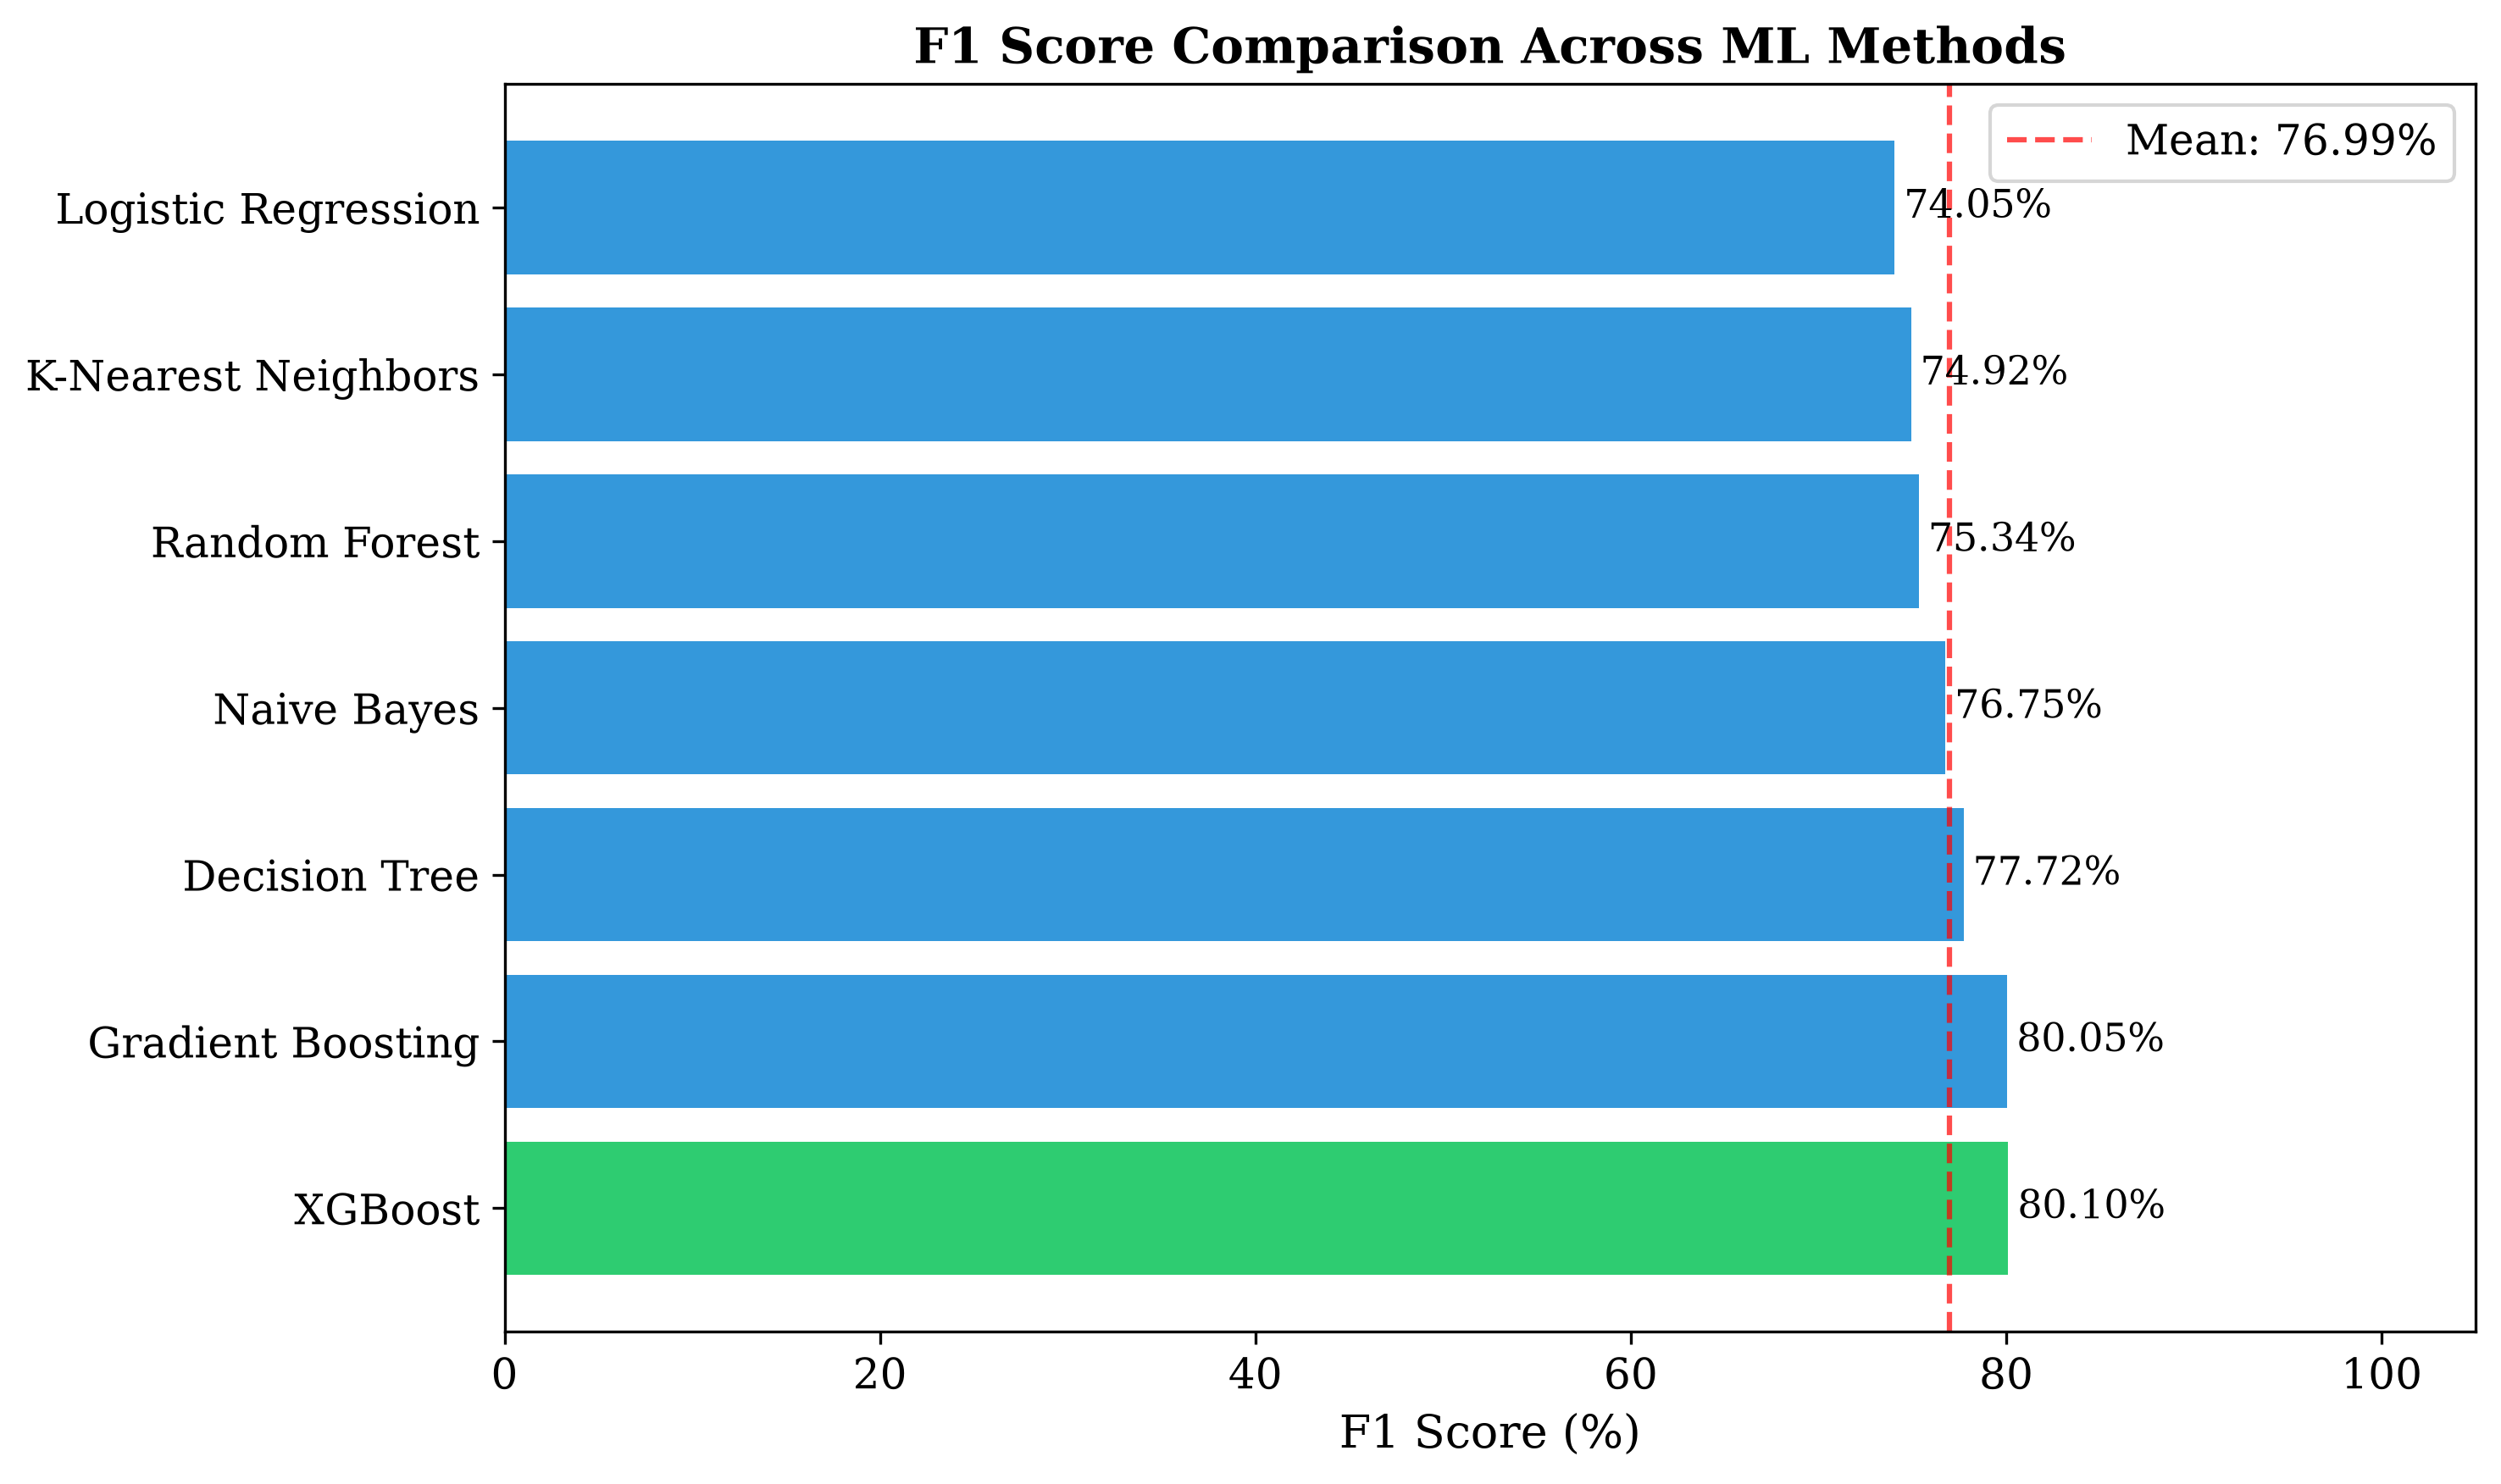

Figure 1 saved


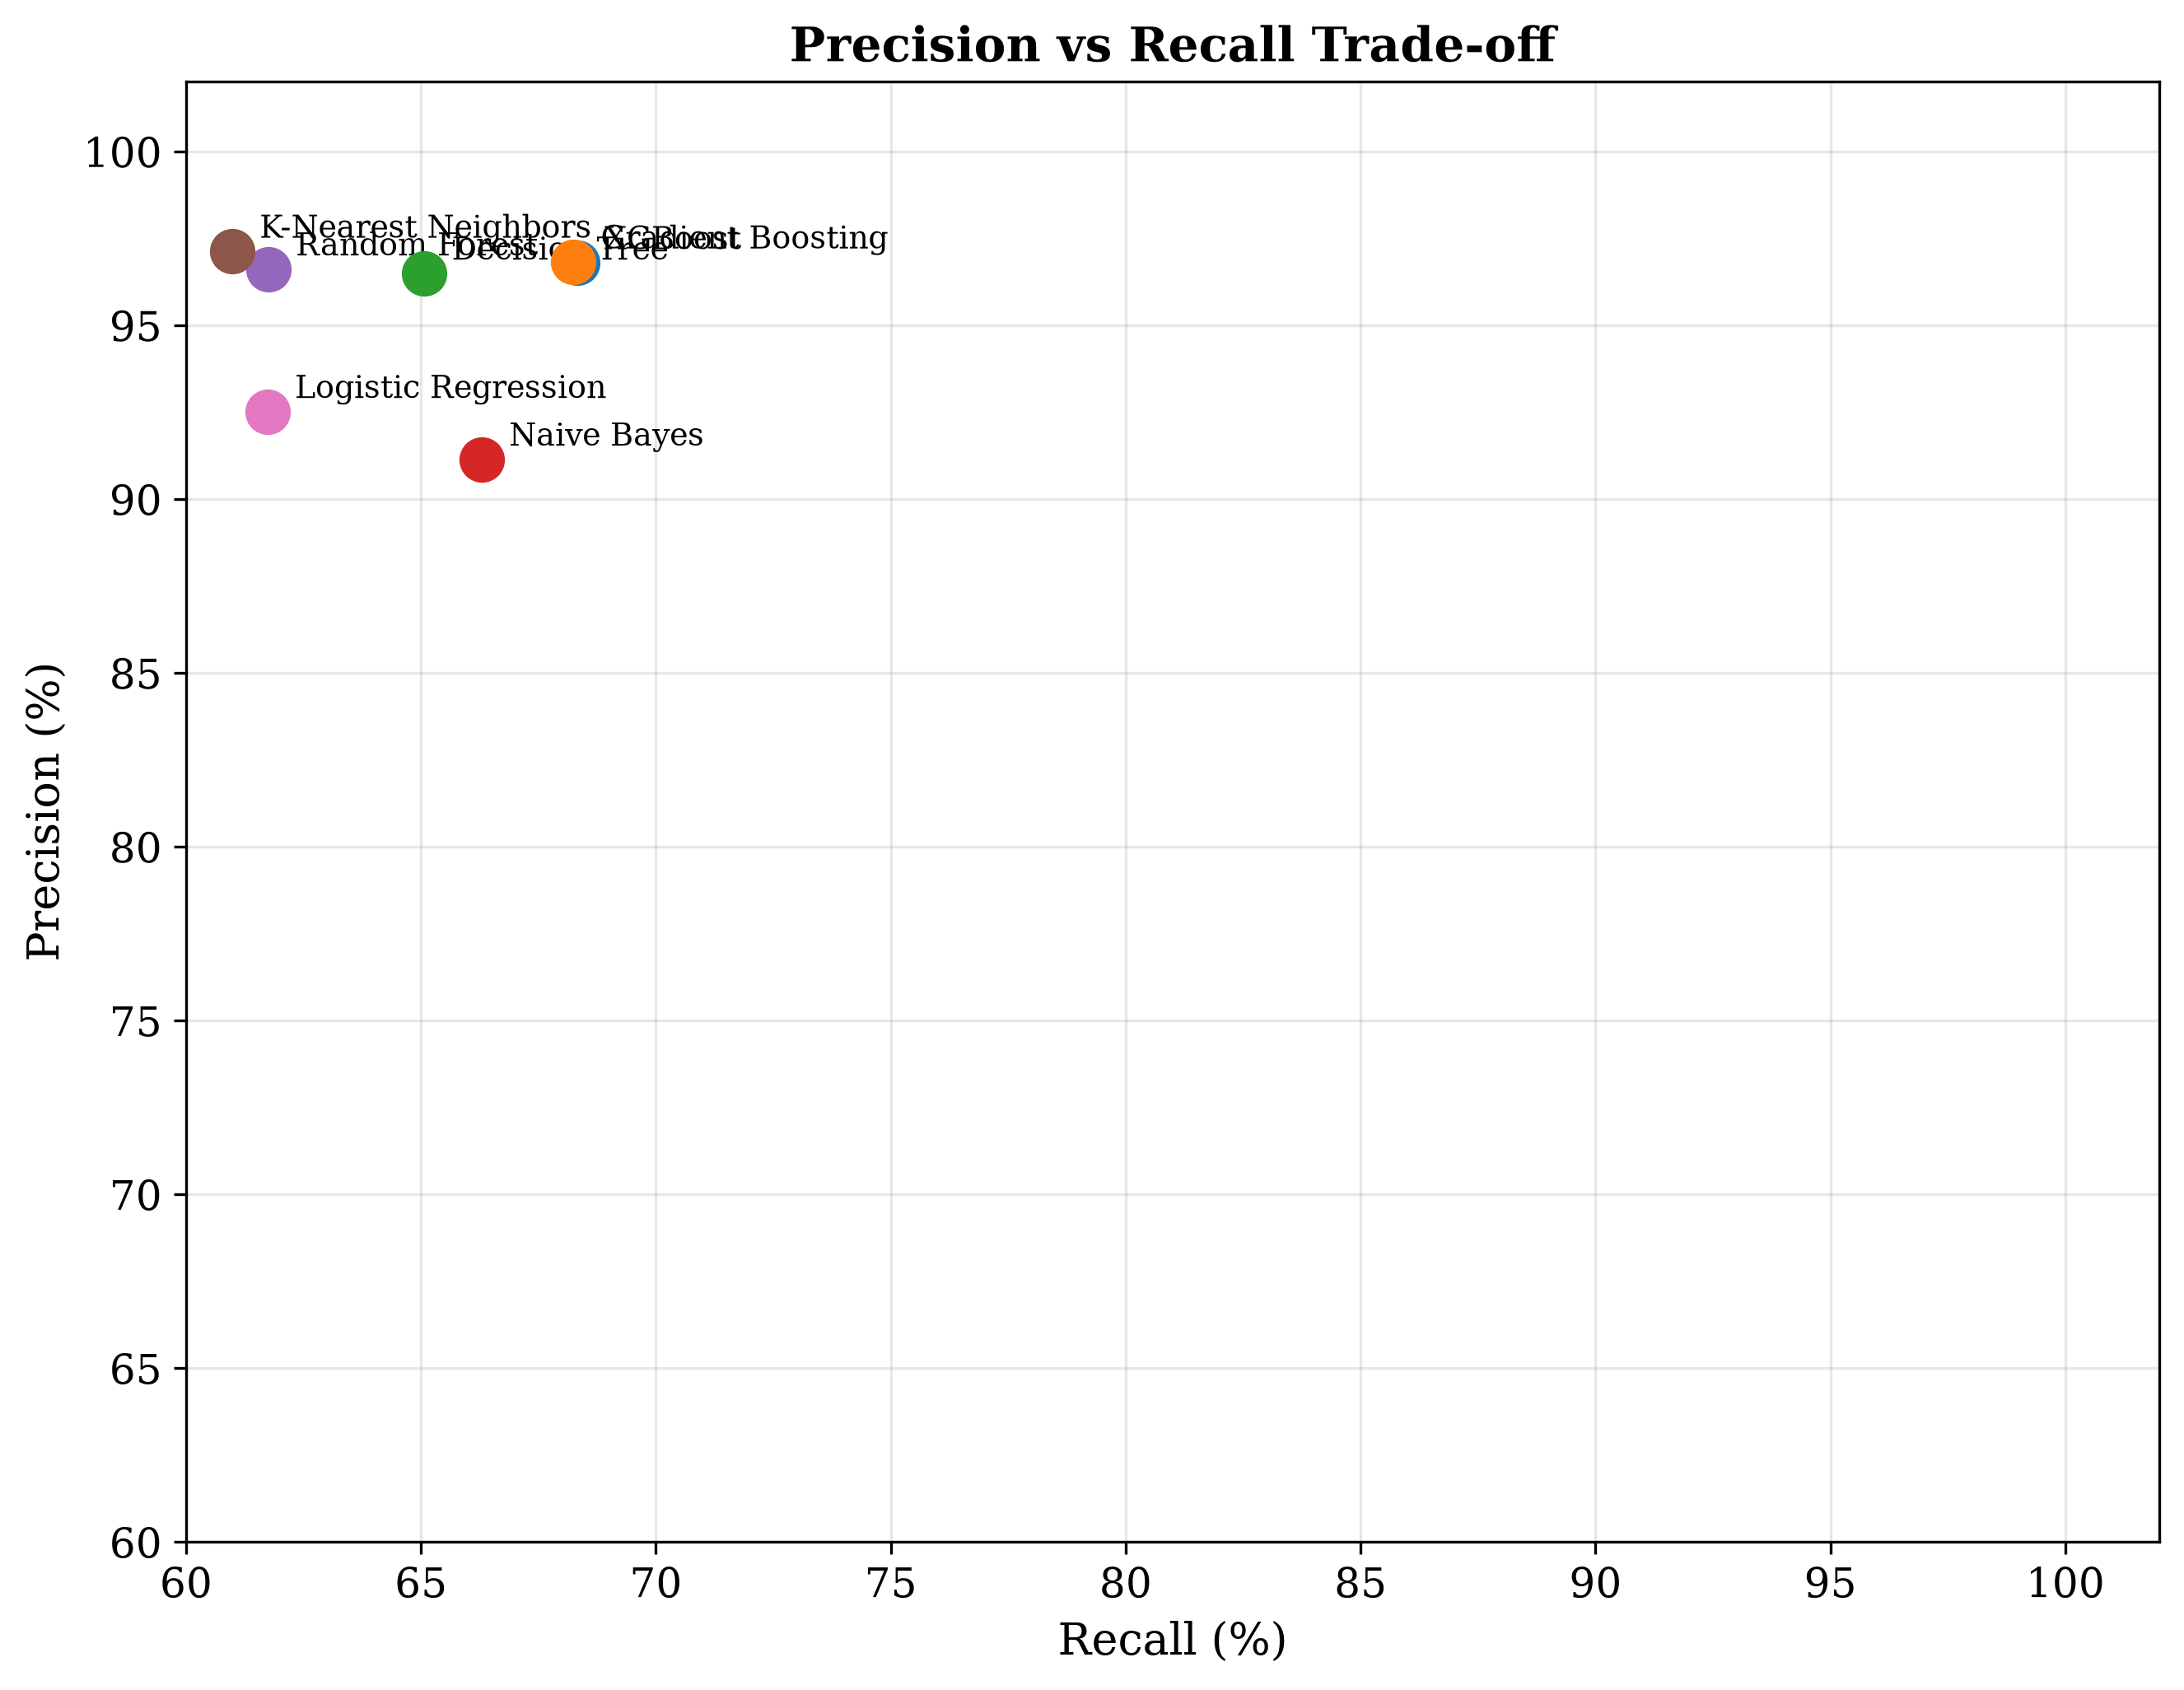

Figure 2 saved


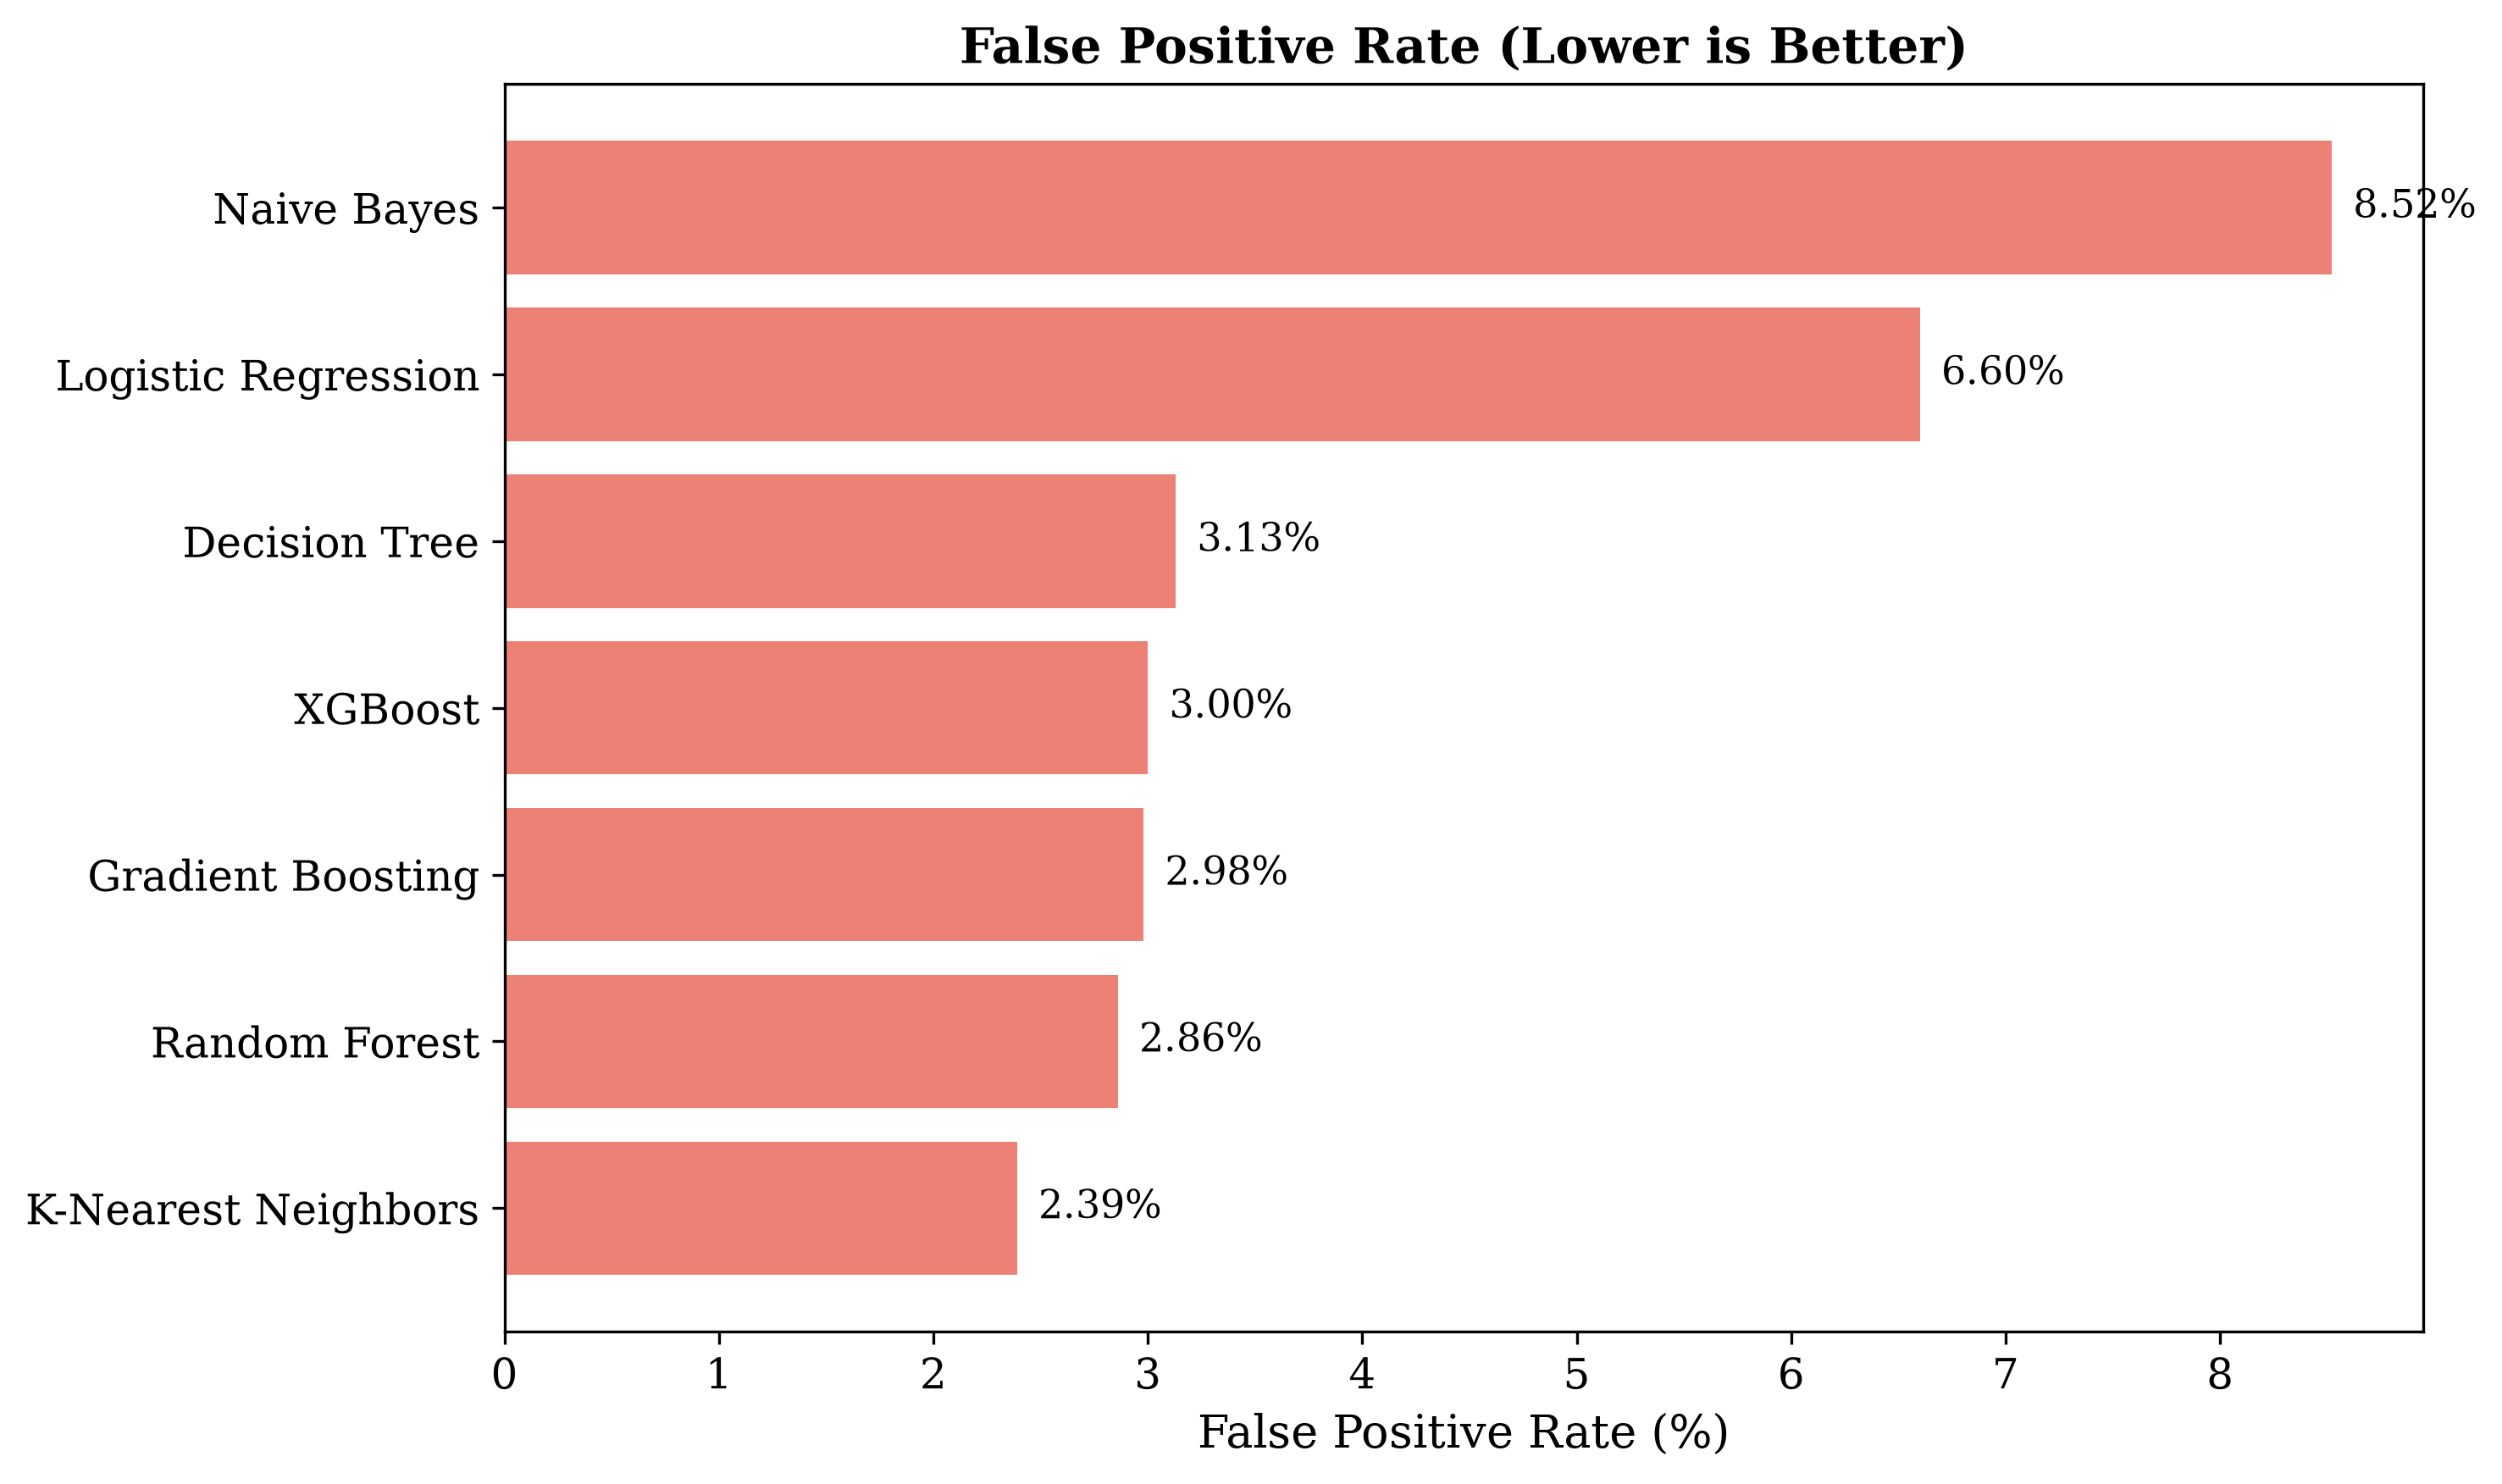

Figure 3 saved


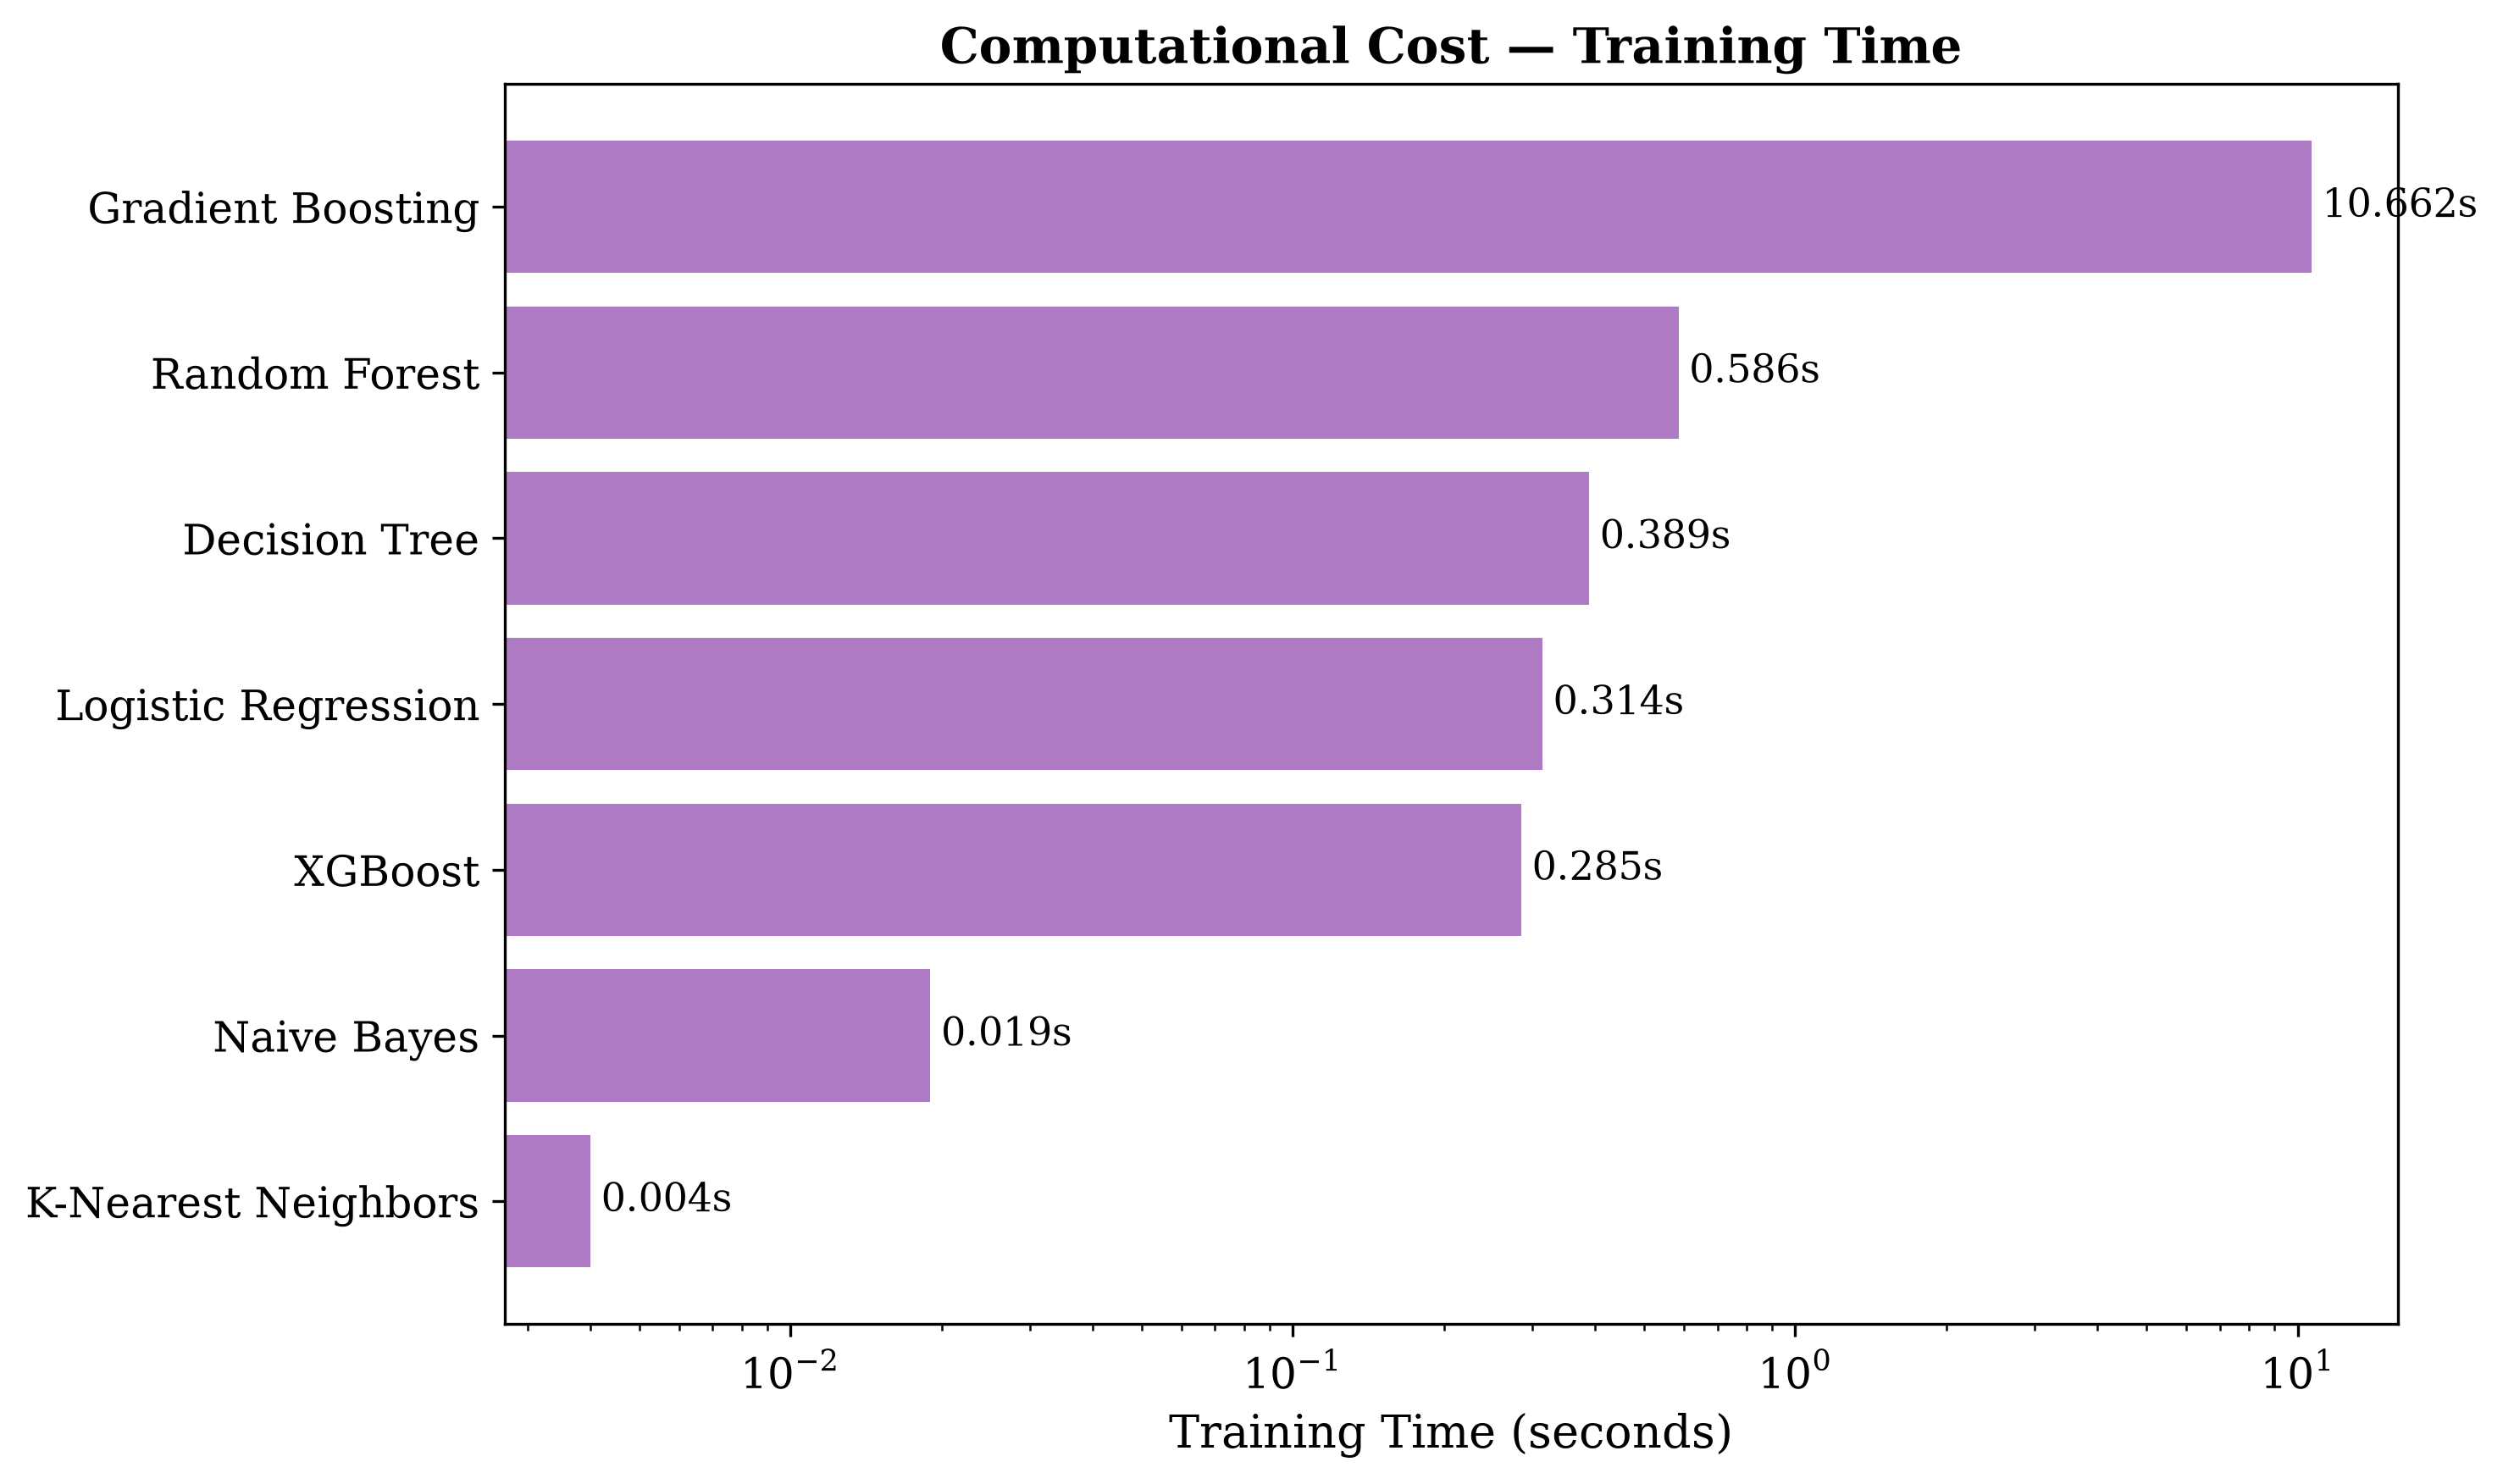

Figure 4 saved


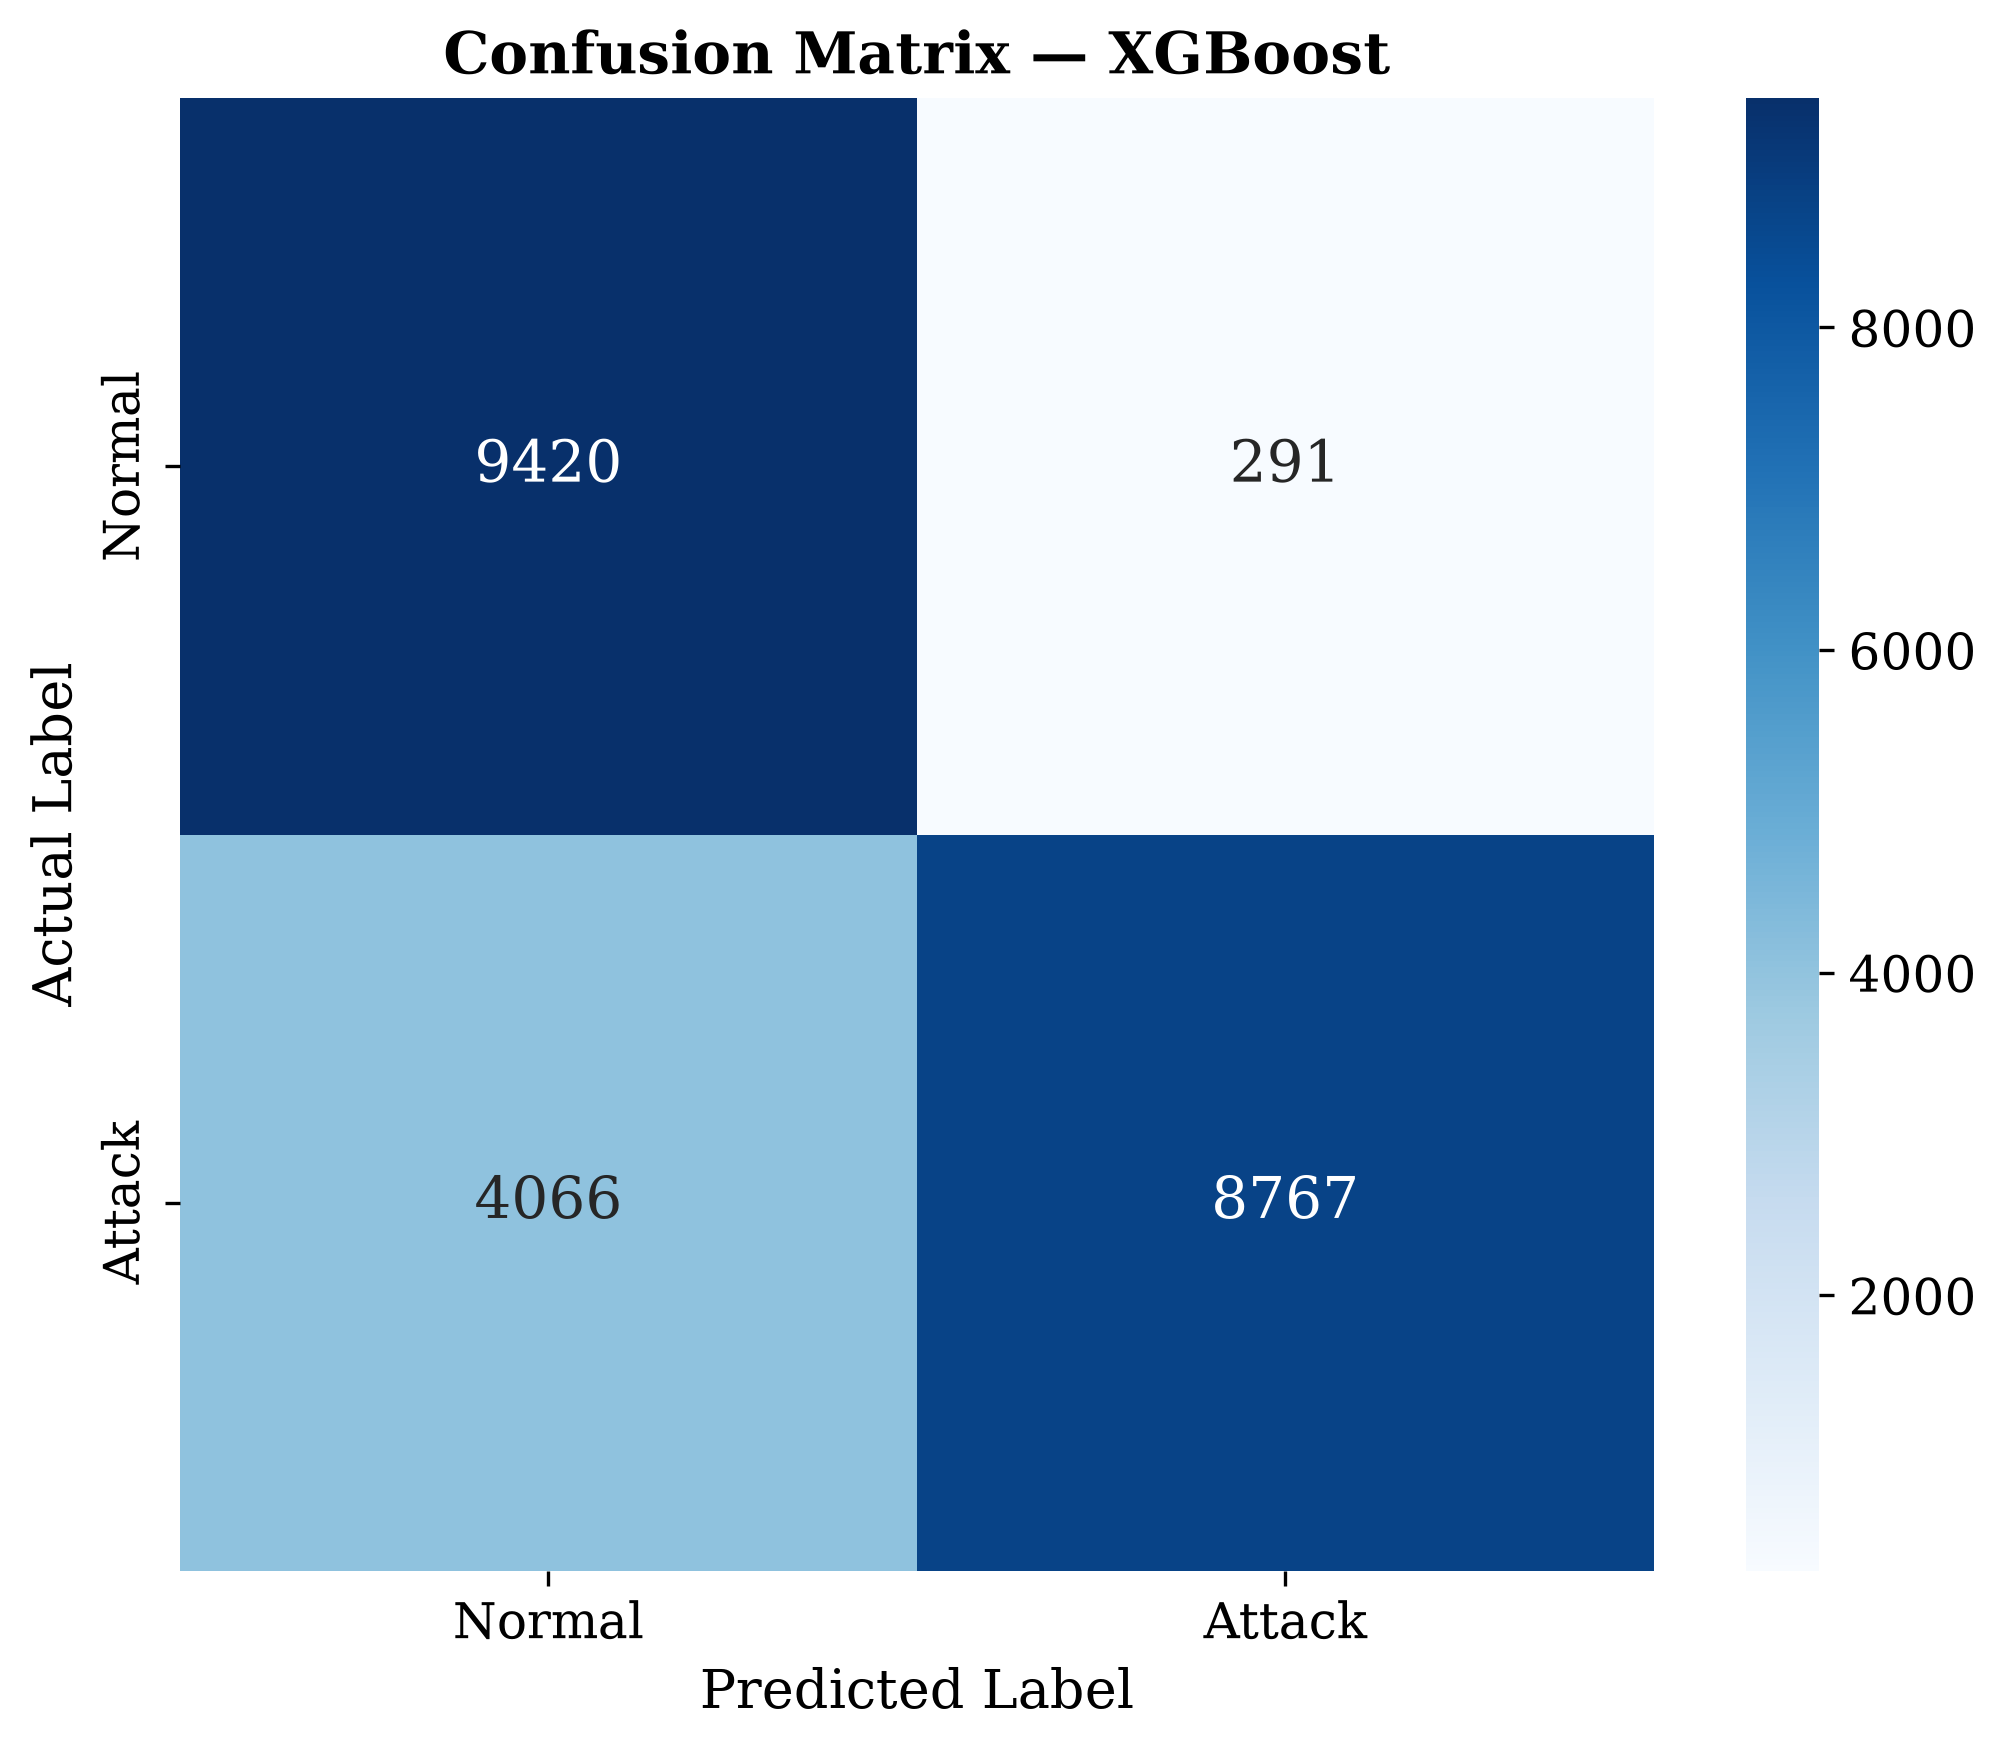

Figure 5 saved


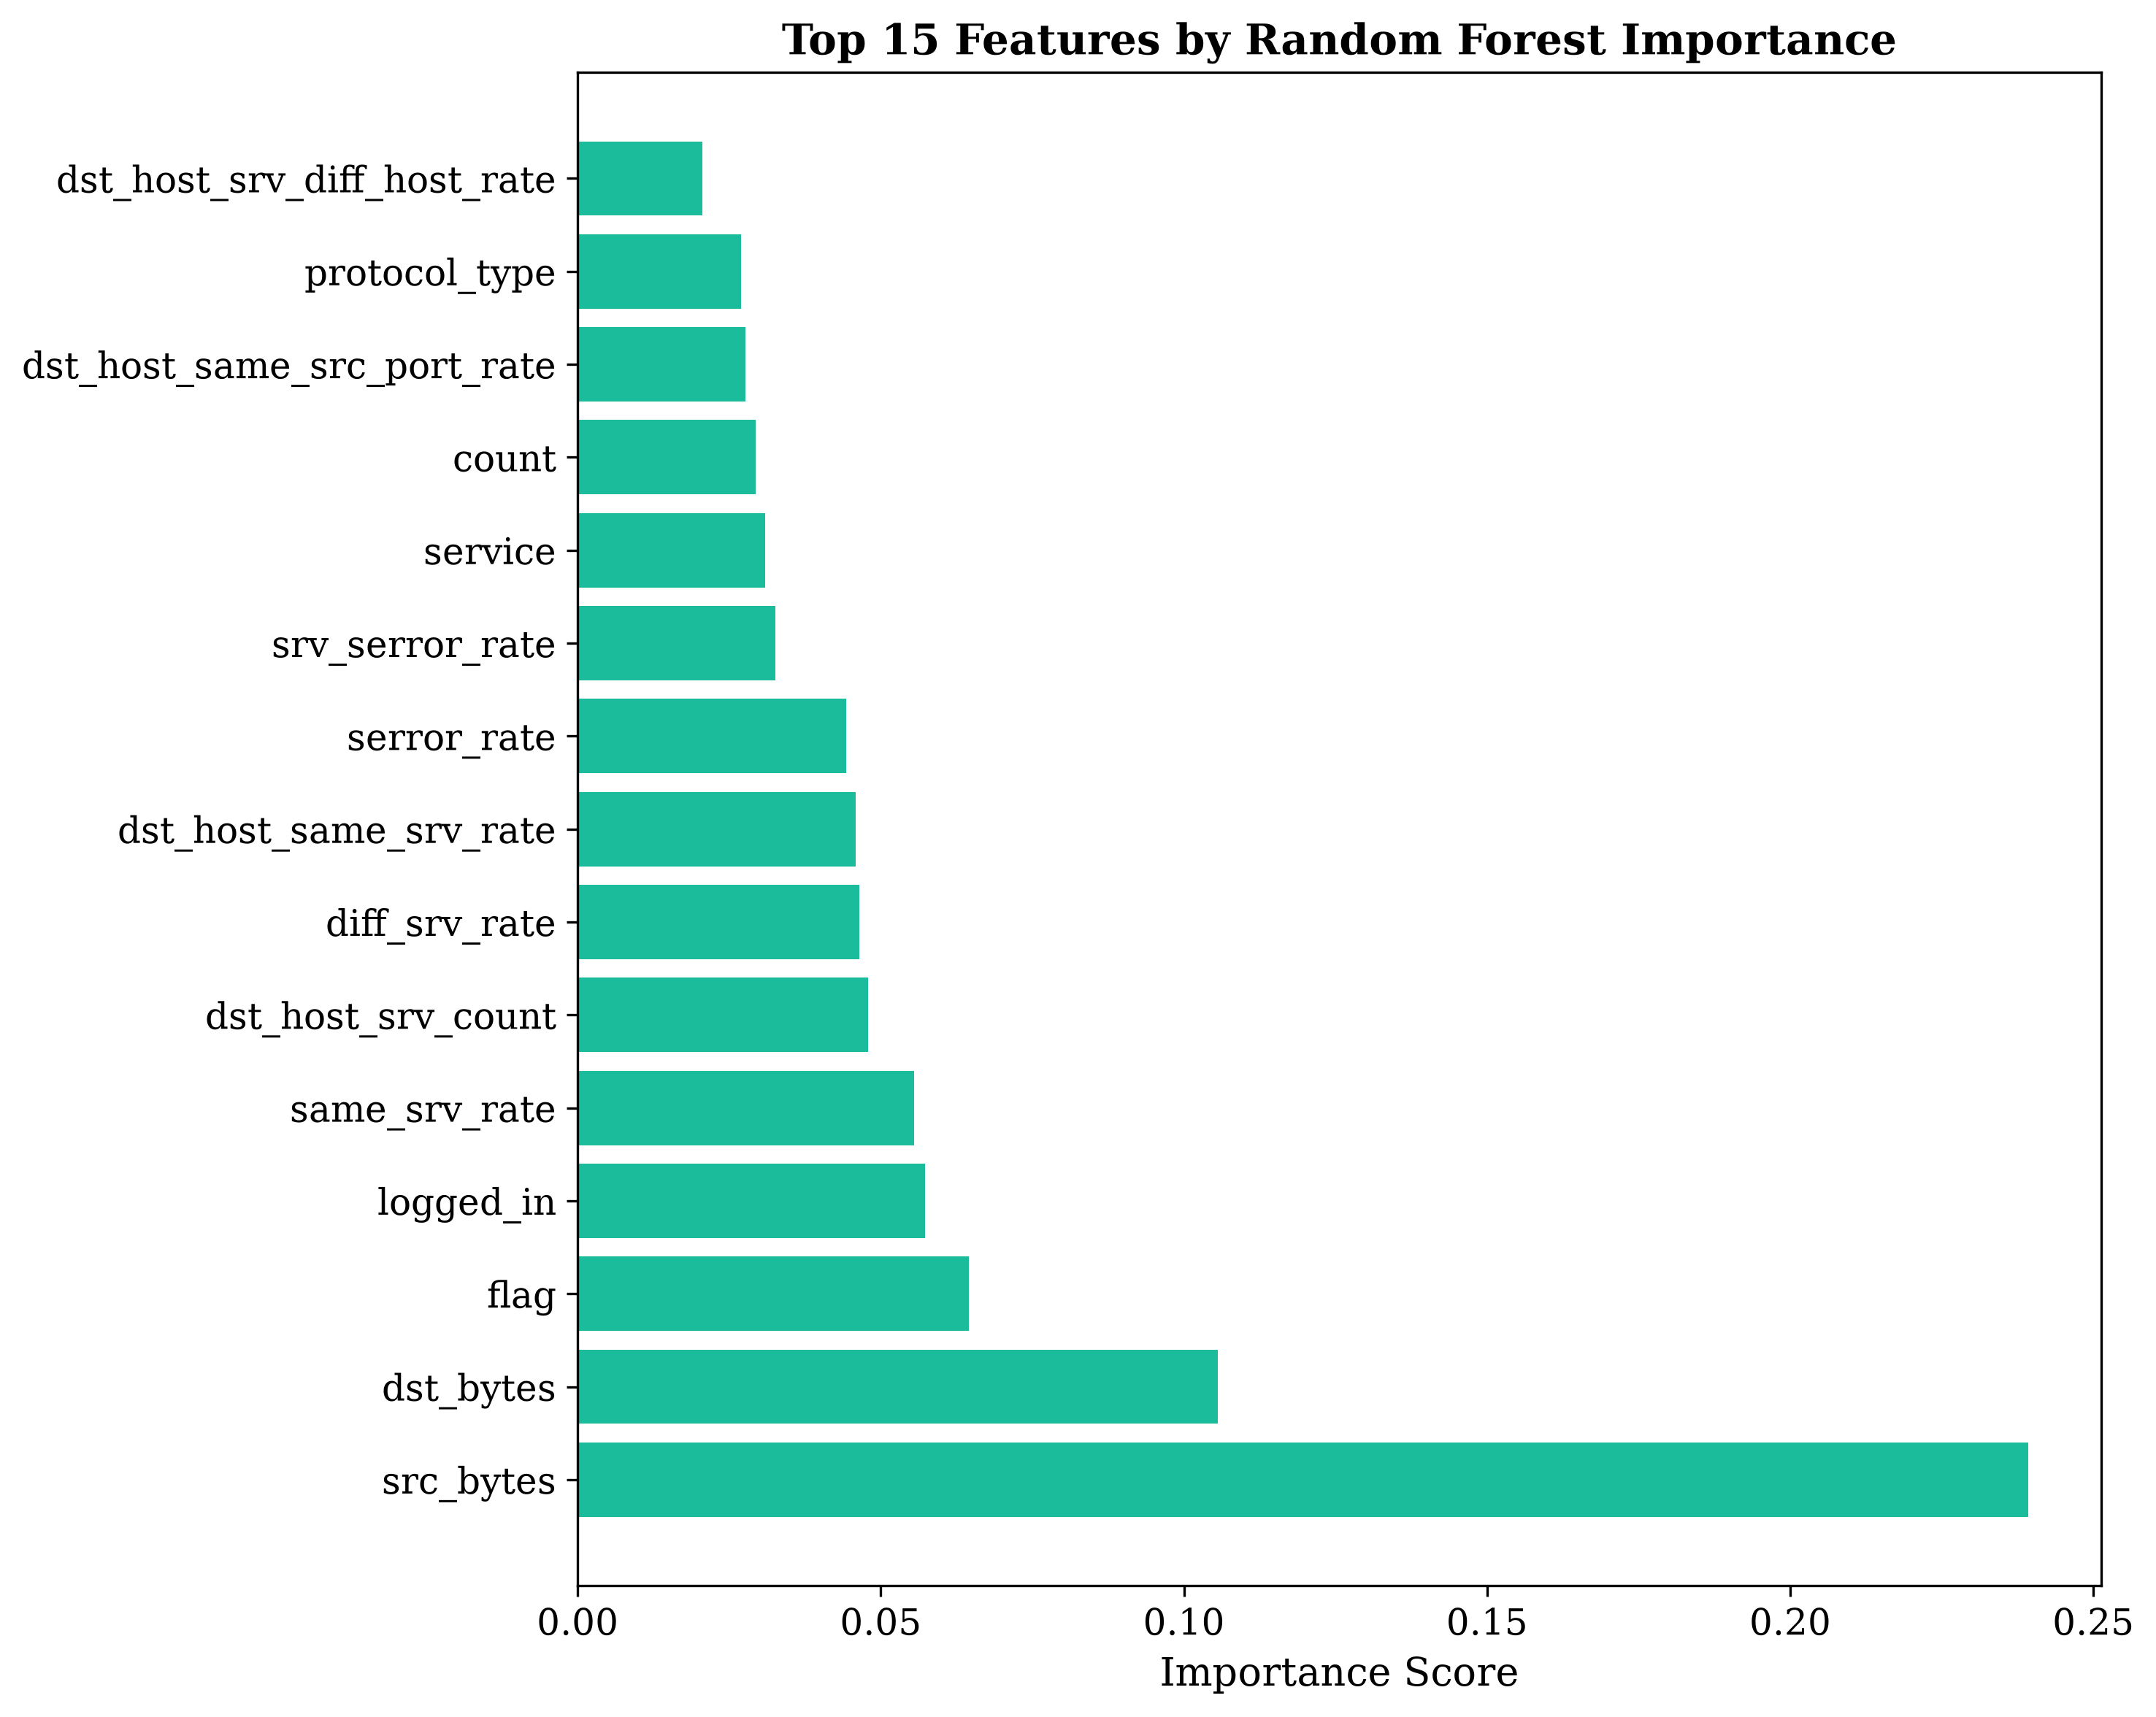

Figure 6 saved

All figures saved to ../figures
These are publication-ready at 300 DPI


In [ ]:
# Cell 8 — Generate All Figures for Paper

import matplotlib.pyplot as plt
import seaborn as sns
import os

figures_dir = '../figures'
os.makedirs(figures_dir, exist_ok=True)

# Set style for publication-quality figures
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# ── FIGURE 1: F1 Score Comparison ──
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#2ecc71' if x == results_df['F1_Score'].max() else '#3498db' 
          for x in results_df['F1_Score']]

bars = ax.barh(results_df['Model'], results_df['F1_Score'], color=colors)
ax.set_xlabel('F1 Score (%)', fontsize=13)
ax.set_title('F1 Score Comparison Across ML Methods', fontsize=14, fontweight='bold')
ax.set_xlim(0, 105)

# Add value labels on bars
for bar, val in zip(bars, results_df['F1_Score']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}%', va='center', fontsize=11)

ax.axvline(x=results_df['F1_Score'].mean(), color='red', 
           linestyle='--', alpha=0.7, label=f'Mean: {results_df["F1_Score"].mean():.2f}%')
ax.legend()
plt.tight_layout()
plt.savefig(f'{figures_dir}/fig1_f1_comparison.png')
plt.show()
print("Figure 1 saved")

# ── FIGURE 2: Precision-Recall Trade-off ──
fig, ax = plt.subplots(figsize=(9, 7))

for _, row in results_df.iterrows():
    ax.scatter(row['Recall'], row['Precision'], s=150, zorder=5)
    ax.annotate(row['Model'], (row['Recall'], row['Precision']),
                textcoords="offset points", xytext=(8, 4), fontsize=9)

ax.set_xlabel('Recall (%)', fontsize=13)
ax.set_ylabel('Precision (%)', fontsize=13)
ax.set_title('Precision vs Recall Trade-off', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_xlim(60, 102)
ax.set_ylim(60, 102)
plt.tight_layout()
plt.savefig(f'{figures_dir}/fig2_precision_recall.png')
plt.show()
print("Figure 2 saved")

# ── FIGURE 3: False Positive Rate Comparison ──
fig, ax = plt.subplots(figsize=(10, 6))

colors_fpr = ['#e74c3c' if x == results_df['False_Positive_Rate'].max() 
              else '#e67e22' for x in results_df['False_Positive_Rate']]

fpr_sorted = results_df.sort_values('False_Positive_Rate')
bars = ax.barh(fpr_sorted['Model'], fpr_sorted['False_Positive_Rate'], 
               color='#e74c3c', alpha=0.7)
ax.set_xlabel('False Positive Rate (%)', fontsize=13)
ax.set_title('False Positive Rate (Lower is Better)', fontsize=14, fontweight='bold')

for bar, val in zip(bars, fpr_sorted['False_Positive_Rate']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}%', va='center', fontsize=11)

plt.tight_layout()
plt.savefig(f'{figures_dir}/fig3_false_positive_rate.png')
plt.show()
print("Figure 3 saved")

# ── FIGURE 4: Training Time Comparison ──
fig, ax = plt.subplots(figsize=(10, 6))

time_sorted = results_df.sort_values('Train_Time_Sec')
bars = ax.barh(time_sorted['Model'], time_sorted['Train_Time_Sec'],
               color='#9b59b6', alpha=0.8)
ax.set_xlabel('Training Time (seconds)', fontsize=13)
ax.set_title('Computational Cost — Training Time', fontsize=14, fontweight='bold')
ax.set_xscale('log')  # Log scale because times vary widely

for bar, val in zip(bars, time_sorted['Train_Time_Sec']):
    ax.text(bar.get_width() * 1.05, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}s', va='center', fontsize=11)

plt.tight_layout()
plt.savefig(f'{figures_dir}/fig4_training_time.png')
plt.show()
print("Figure 4 saved")

# ── FIGURE 5: Confusion Matrix for Best Model ──
best_model_name = results_df.iloc[0]['Model']
best_y_pred = all_predictions[best_model_name]

cm = confusion_matrix(y_test, best_y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'],
            ax=ax, annot_kws={"size": 14})
ax.set_ylabel('Actual Label', fontsize=13)
ax.set_xlabel('Predicted Label', fontsize=13)
ax.set_title(f'Confusion Matrix — {best_model_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figures_dir}/fig5_confusion_matrix.png')
plt.show()
print("Figure 5 saved")

# ── FIGURE 6: Feature Importance ──
fig, ax = plt.subplots(figsize=(10, 8))
top_15 = feature_importance_df.nlargest(15, 'RF_Importance')
ax.barh(top_15['Feature'], top_15['RF_Importance'], color='#1abc9c')
ax.set_xlabel('Importance Score', fontsize=13)
ax.set_title('Top 15 Features by Random Forest Importance', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figures_dir}/fig6_feature_importance.png')
plt.show()
print("Figure 6 saved")

print("\nAll figures saved to", figures_dir)
print("These are publication-ready at 300 DPI")

In [ ]:
# Cell 9 — Save Results to CSV

results_df.to_csv('../results/main_results.csv', index=False)
cv_summary.to_csv('../results/cross_validation.csv')
feature_importance_df.to_csv('../results/feature_importance.csv', index=False)

print("All results saved to ../results/")
print("\nFiles created:")
print("  - main_results.csv — your main results table")
print("  - cross_validation.csv — statistical validation")
print("  - feature_importance.csv — feature analysis")

print("\n=== FINAL SUMMARY FOR PAPER ===")
print(f"\nBest model: {results_df.iloc[0]['Model']}")
print(f"Best F1 Score: {results_df.iloc[0]['F1_Score']}%")
print(f"Best Accuracy: {results_df.iloc[0]['Accuracy']}%")
print(f"Best FPR: {results_df[results_df['False_Positive_Rate']==results_df['False_Positive_Rate'].min()].iloc[0]['Model']} with {results_df['False_Positive_Rate'].min()}%")
print(f"Fastest model: {results_df.loc[results_df['Train_Time_Sec'].idxmin(), 'Model']} at {results_df['Train_Time_Sec'].min():.3f}s")

All results saved to ../results/

Files created:
  - main_results.csv — your main results table
  - cross_validation.csv — statistical validation
  - feature_importance.csv — feature analysis

=== FINAL SUMMARY FOR PAPER ===

Best model: XGBoost
Best F1 Score: 80.1%
Best Accuracy: 80.67%
Best FPR: K-Nearest Neighbors with 2.39%
Fastest model: K-Nearest Neighbors at 0.004s


In [ ]:
# CELL 10 — Multi-Class Classification
from sklearn.metrics import f1_score, accuracy_score
import time

# Multi-class label mapping
attack_map = {
    'normal':'normal',
    'neptune':'DoS','back':'DoS','land':'DoS','pod':'DoS',
    'smurf':'DoS','teardrop':'DoS','mailbomb':'DoS',
    'apache2':'DoS','processtable':'DoS','udpstorm':'DoS',
    'ipsweep':'Probe','nmap':'Probe','portsweep':'Probe',
    'satan':'Probe','mscan':'Probe','saint':'Probe',
    'ftp_write':'R2L','guess_passwd':'R2L','imap':'R2L',
    'multihop':'R2L','phf':'R2L','spy':'R2L','warezclient':'R2L',
    'warezmaster':'R2L','sendmail':'R2L','named':'R2L',
    'snmpgetattack':'R2L','snmpguess':'R2L','worm':'R2L',
    'xlock':'R2L','xsnoop':'R2L','httptunnel':'R2L',
    'buffer_overflow':'U2R','loadmodule':'U2R','perl':'U2R',
    'rootkit':'U2R','ps':'U2R','sqlattack':'U2R','xterm':'U2R'
}

# Create multi-class labels
train_df['attack_cat'] = train_df['label'].map(lambda x: attack_map.get(x, 'other'))
test_df['attack_cat']  = test_df['label'].map(lambda x: attack_map.get(x, 'other'))

# Encode to numbers
from sklearn.preprocessing import LabelEncoder
le_cat = LabelEncoder()
combined_cats = pd.concat([train_df['attack_cat'], test_df['attack_cat']])
le_cat.fit(combined_cats)
y_train_mc = le_cat.transform(train_df['attack_cat'])
y_test_mc  = le_cat.transform(test_df['attack_cat'])

classes = le_cat.classes_
print("Attack categories:", classes)
print("\nTest set distribution:")
for cls, cnt in zip(classes, np.bincount(y_test_mc)):
    print(f"  {cls}: {cnt} samples")

# Run all 7 models on multi-class task
mc_results = []

for name, model in models.items():
    print(f"\nTraining {name} (multi-class)...")
    
    # Re-create model to avoid state from binary training
    model_fresh = model.__class__(**model.get_params())
    
    t0 = time.time()
    model_fresh.fit(X_train_scaled, y_train_mc)
    train_time = time.time() - t0
    
    y_pred_mc = model_fresh.predict(X_test_scaled)
    
    macro_f1    = f1_score(y_test_mc, y_pred_mc, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_test_mc, y_pred_mc, average='weighted', zero_division=0)
    acc         = accuracy_score(y_test_mc, y_pred_mc)
    
    # Per-class F1
    f1_per = f1_score(y_test_mc, y_pred_mc, average=None,
                      labels=list(range(len(classes))), zero_division=0)
    
    row = {'Model': name, 'Accuracy': round(acc*100,2),
           'Macro_F1': round(macro_f1*100,2),
           'Weighted_F1': round(weighted_f1*100,2),
           'Train_Time': round(train_time,3)}
    for i, cls in enumerate(classes):
        row[f'F1_{cls}'] = round(f1_per[i]*100, 2)
    
    mc_results.append(row)
    print(f"  Macro F1: {macro_f1*100:.2f}%  Accuracy: {acc*100:.2f}%")

mc_df = pd.DataFrame(mc_results).sort_values('Macro_F1', ascending=False)
mc_df.to_csv('../results/multiclass_results.csv', index=False)

print("\n=== MULTI-CLASS RESULTS ===")
print(mc_df[['Model','Accuracy','Macro_F1','F1_DoS',
             'F1_Probe','F1_R2L','F1_U2R','F1_normal']].to_string(index=False))

Attack categories: ['DoS' 'Probe' 'R2L' 'U2R' 'normal']

Test set distribution:
  DoS: 7458 samples
  Probe: 2421 samples
  R2L: 2887 samples
  U2R: 67 samples
  normal: 9711 samples

Training Decision Tree (multi-class)...
  Macro F1: 57.40%  Accuracy: 76.90%

Training Random Forest (multi-class)...
  Macro F1: 50.40%  Accuracy: 75.08%

Training Naive Bayes (multi-class)...
  Macro F1: 34.95%  Accuracy: 43.31%

Training K-Nearest Neighbors (multi-class)...
  Macro F1: 56.93%  Accuracy: 74.98%

Training Logistic Regression (multi-class)...
  Macro F1: 54.53%  Accuracy: 76.14%

Training XGBoost (multi-class)...
  Macro F1: 54.15%  Accuracy: 76.12%

Training Gradient Boosting (multi-class)...
  Macro F1: 58.03%  Accuracy: 76.74%

=== MULTI-CLASS RESULTS ===
              Model  Accuracy  Macro_F1  F1_DoS  F1_Probe  F1_R2L  F1_U2R  F1_normal
  Gradient Boosting     76.74     58.03   88.52     72.60   12.58   37.36      79.10
      Decision Tree     76.90     57.40   87.38     66.49   21.1

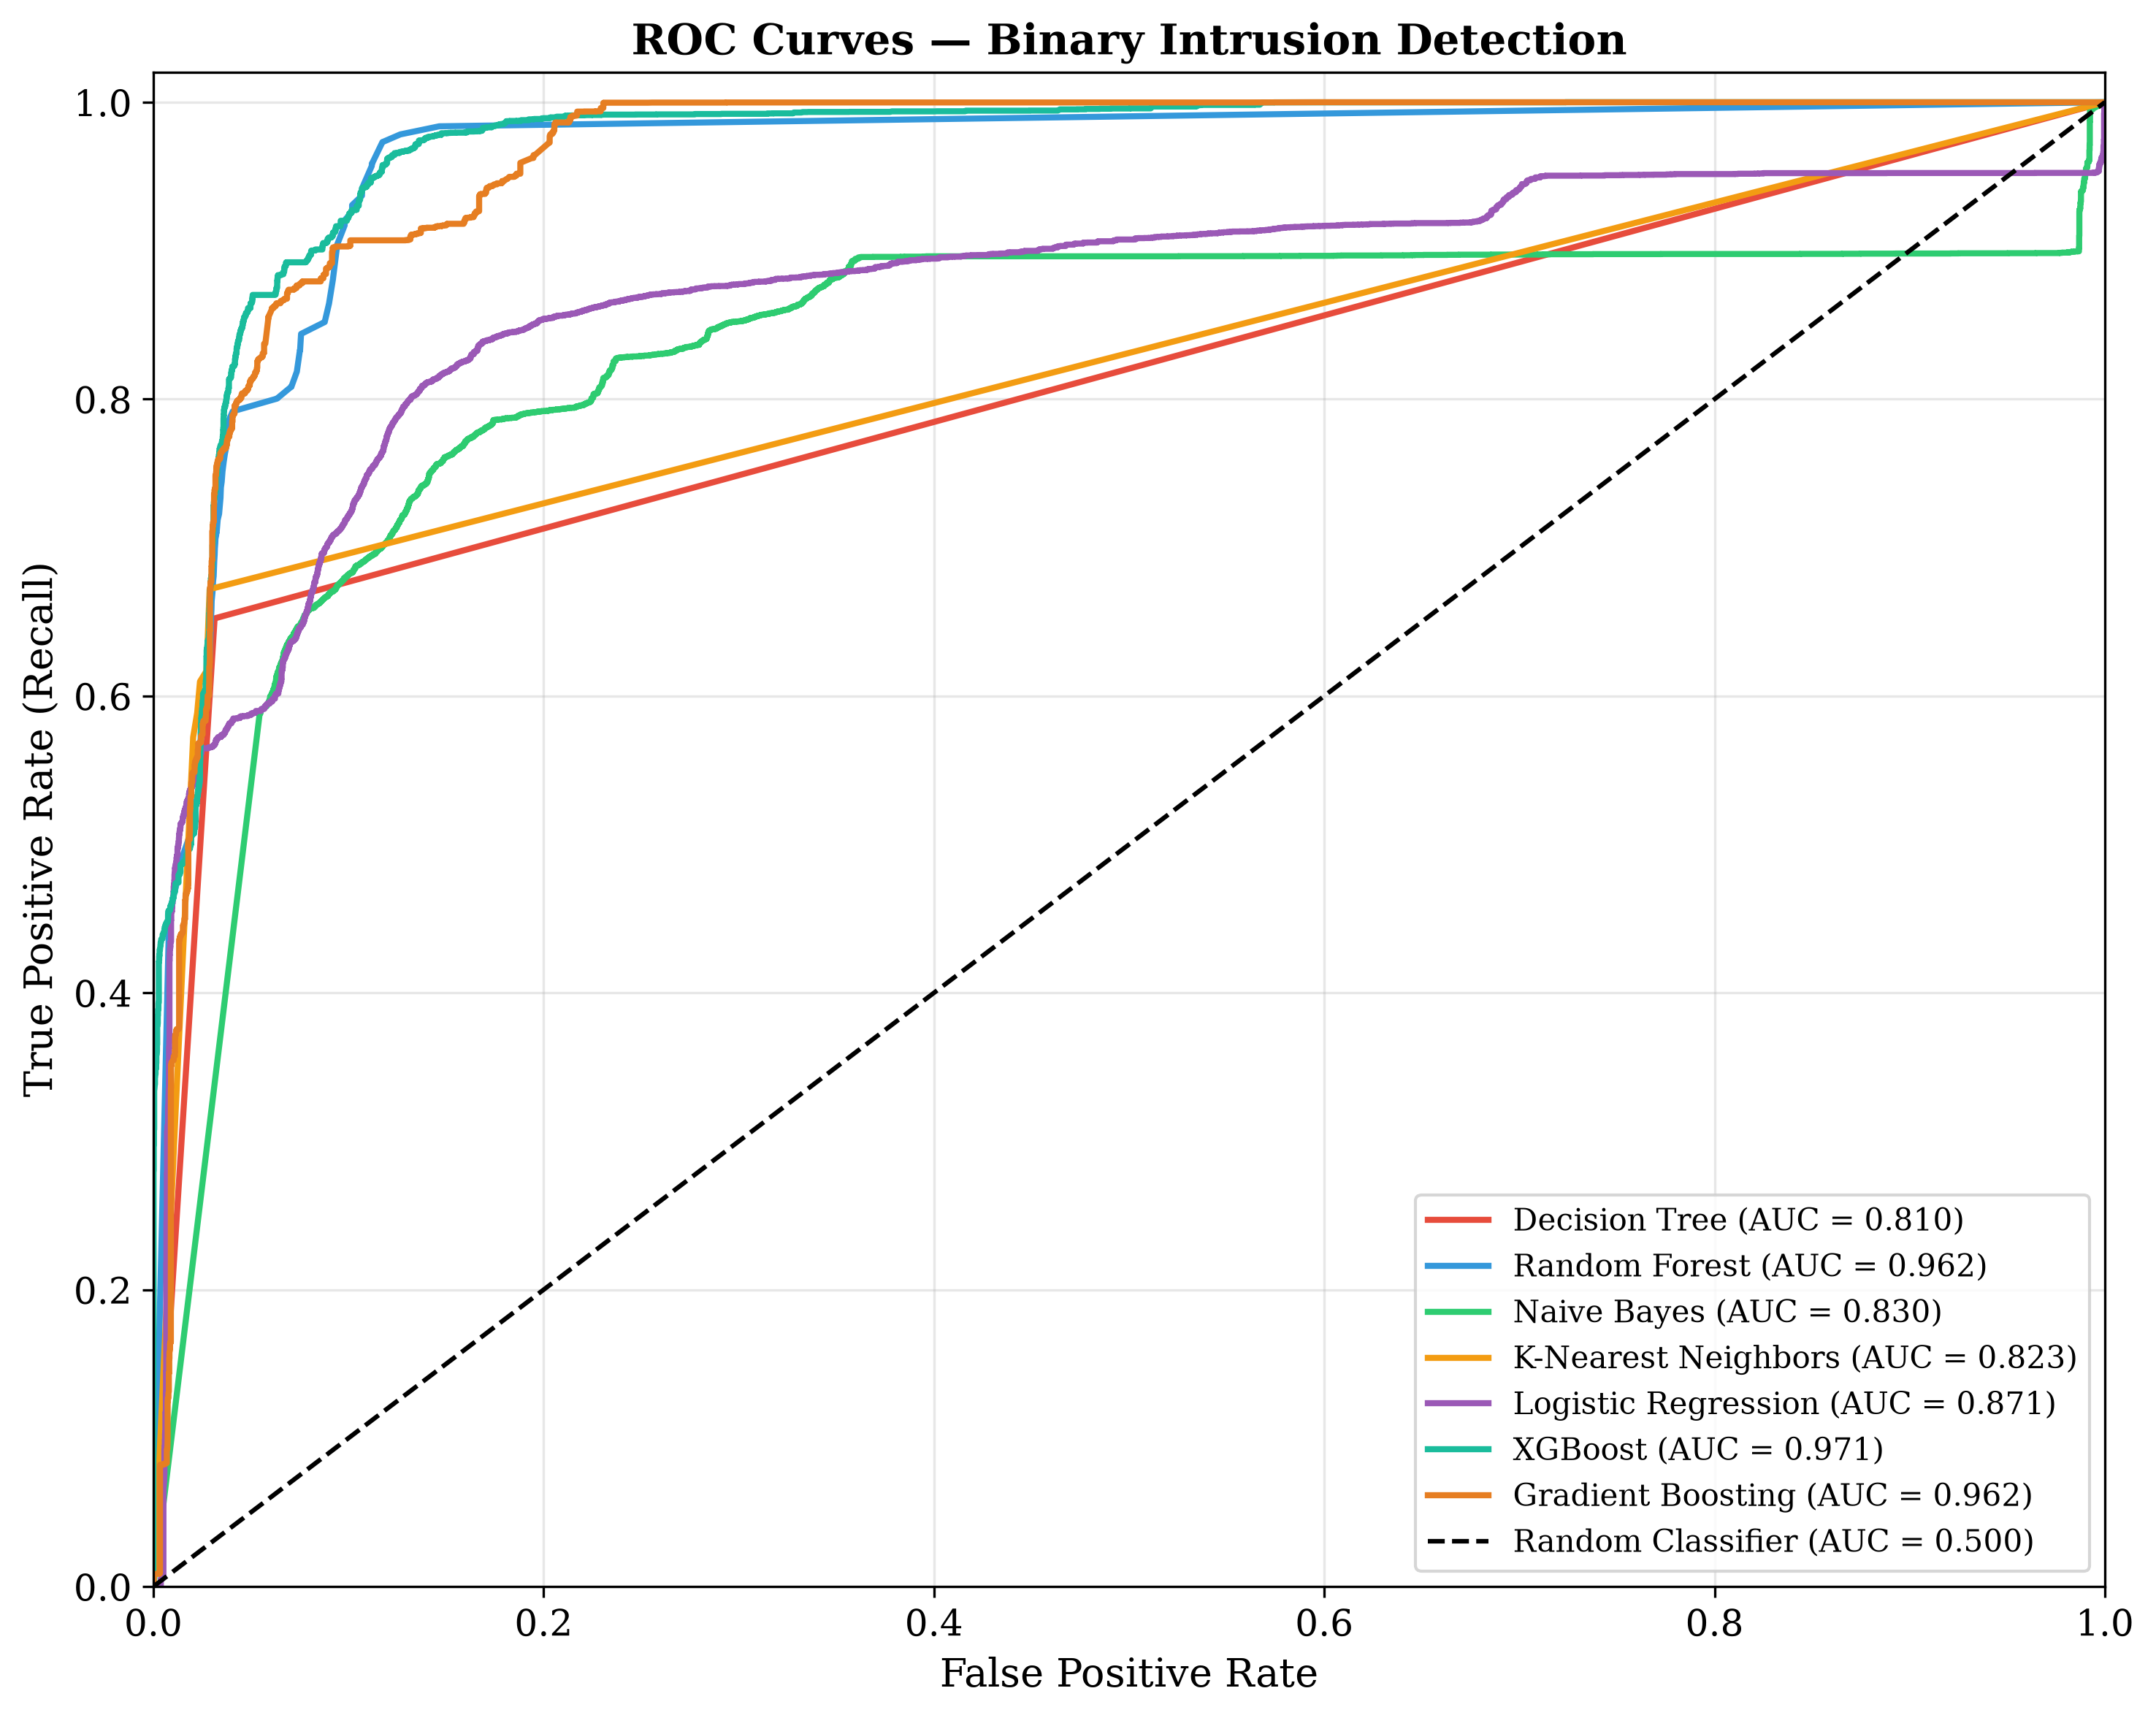

AUC Scores:
              Model    AUC
            XGBoost 0.9706
  Gradient Boosting 0.9625
      Random Forest 0.9621
Logistic Regression 0.8714
        Naive Bayes 0.8299
K-Nearest Neighbors 0.8228
      Decision Tree 0.8104


In [ ]:
# CELL 11 — ROC Curves
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))
colors_roc = ['#e74c3c','#3498db','#2ecc71','#f39c12',
               '#9b59b6','#1abc9c','#e67e22']
roc_data = []

for (name, model), color in zip(trained_models.items(), colors_roc):
    # Get probability scores (confidence, not just 0/1 prediction)
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_score = model.decision_function(X_test_scaled)
    
    fpr_arr, tpr_arr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr_arr, tpr_arr)
    roc_data.append({'Model': name, 'AUC': round(roc_auc, 4)})
    
    ax.plot(fpr_arr, tpr_arr, color=color, lw=2,
            label=f'{name} (AUC = {roc_auc:.3f})')

ax.plot([0,1],[0,1],'k--', lw=1.5, label='Random Classifier (AUC = 0.500)')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.02])
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate (Recall)', fontsize=13)
ax.set_title('ROC Curves — Binary Intrusion Detection', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/fig7_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()

roc_df = pd.DataFrame(roc_data).sort_values('AUC', ascending=False)
roc_df.to_csv('../results/roc_auc.csv', index=False)
print("AUC Scores:")
print(roc_df.to_string(index=False))

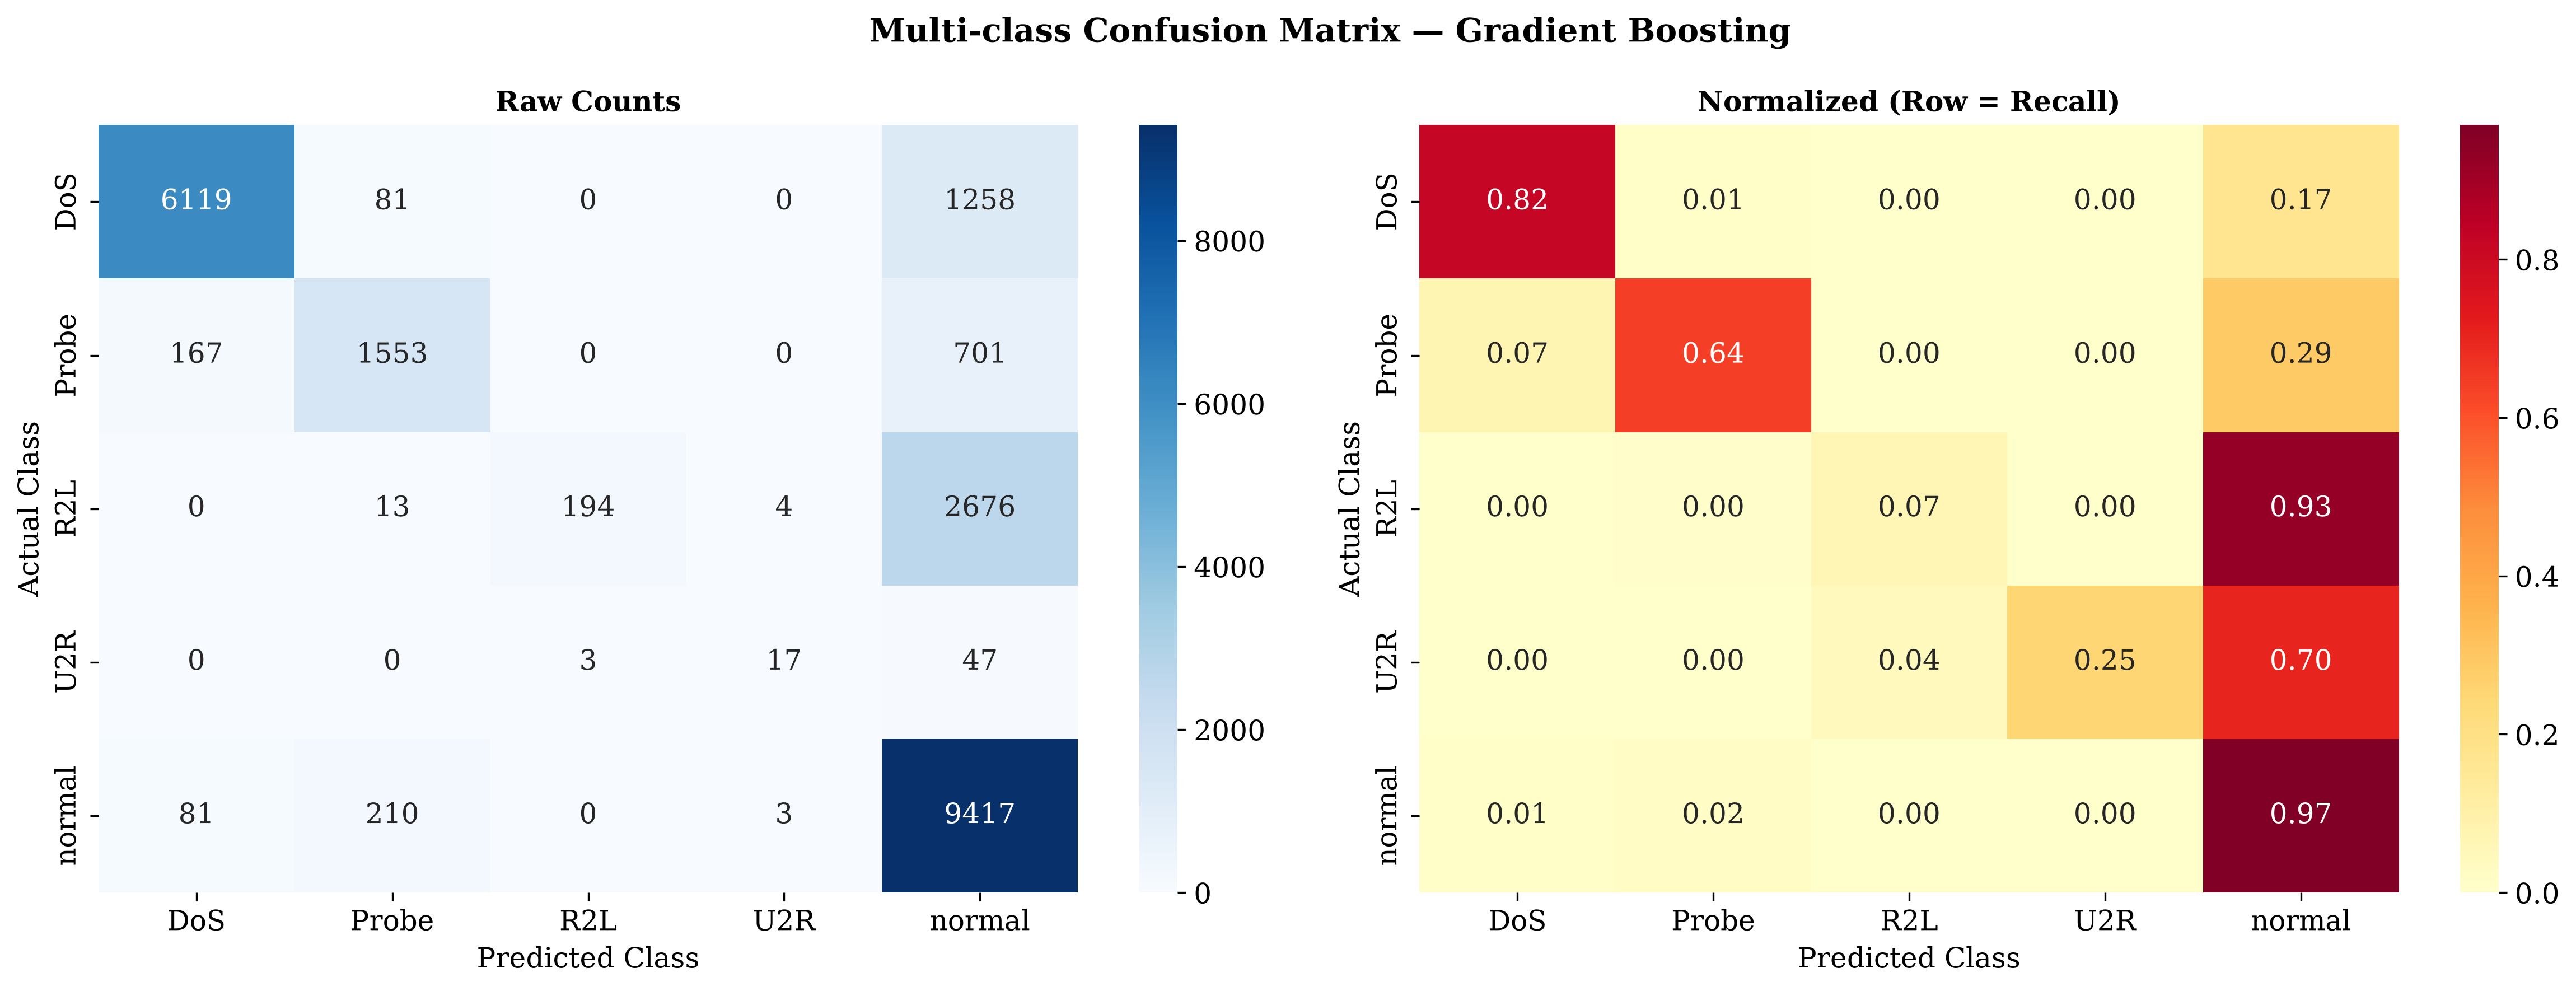

=== DETECTION RATE BY ATTACK CATEGORY ===
DoS: 6119/7458 = 82.0% detected
   → wrongly classified as normal: 1258 (16.9%)
   → wrongly classified as Probe: 81 (1.1%)
Probe: 1553/2421 = 64.1% detected
   → wrongly classified as normal: 701 (29.0%)
   → wrongly classified as DoS: 167 (6.9%)
R2L: 194/2887 = 6.7% detected
   → wrongly classified as normal: 2676 (92.7%)
   → wrongly classified as Probe: 13 (0.5%)
   → wrongly classified as U2R: 4 (0.1%)
U2R: 17/67 = 25.4% detected
   → wrongly classified as normal: 47 (70.1%)
   → wrongly classified as R2L: 3 (4.5%)
normal: 9417/9711 = 97.0% detected
   → wrongly classified as Probe: 210 (2.2%)
   → wrongly classified as DoS: 81 (0.8%)
   → wrongly classified as U2R: 3 (0.0%)


In [ ]:
# CELL 12 — Multi-Class Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Retrain best multi-class model (Gradient Boosting)
from sklearn.ensemble import GradientBoostingClassifier
best_mc_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
best_mc_model.fit(X_train_scaled, y_train_mc)
y_pred_best_mc = best_mc_model.predict(X_test_scaled)

cm = confusion_matrix(y_test_mc, y_pred_best_mc)
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes,
            ax=axes[0], annot_kws={"size": 12})
axes[0].set_ylabel('Actual Class', fontsize=12)
axes[0].set_xlabel('Predicted Class', fontsize=12)
axes[0].set_title('Raw Counts', fontsize=12, fontweight='bold')

# Normalized (recall per class)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=classes, yticklabels=classes,
            ax=axes[1], annot_kws={"size": 12})
axes[1].set_ylabel('Actual Class', fontsize=12)
axes[1].set_xlabel('Predicted Class', fontsize=12)
axes[1].set_title('Normalized (Row = Recall)', fontsize=12, fontweight='bold')

fig.suptitle('Multi-class Confusion Matrix — Gradient Boosting',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig8_multiclass_confusion.png', dpi=300, bbox_inches='tight')
plt.show()

# Print analysis
print("=== DETECTION RATE BY ATTACK CATEGORY ===")
for i, cls in enumerate(classes):
    total = cm[i].sum()
    correct = cm[i][i]
    print(f"{cls}: {correct}/{total} = {correct/total*100:.1f}% detected")
    missed = [(classes[j], cm[i][j]) 
              for j in range(len(classes)) if j != i and cm[i][j] > 0]
    for wrong_cls, count in sorted(missed, key=lambda x: -x[1]):
        print(f"   → wrongly classified as {wrong_cls}: {count} ({count/total*100:.1f}%)")

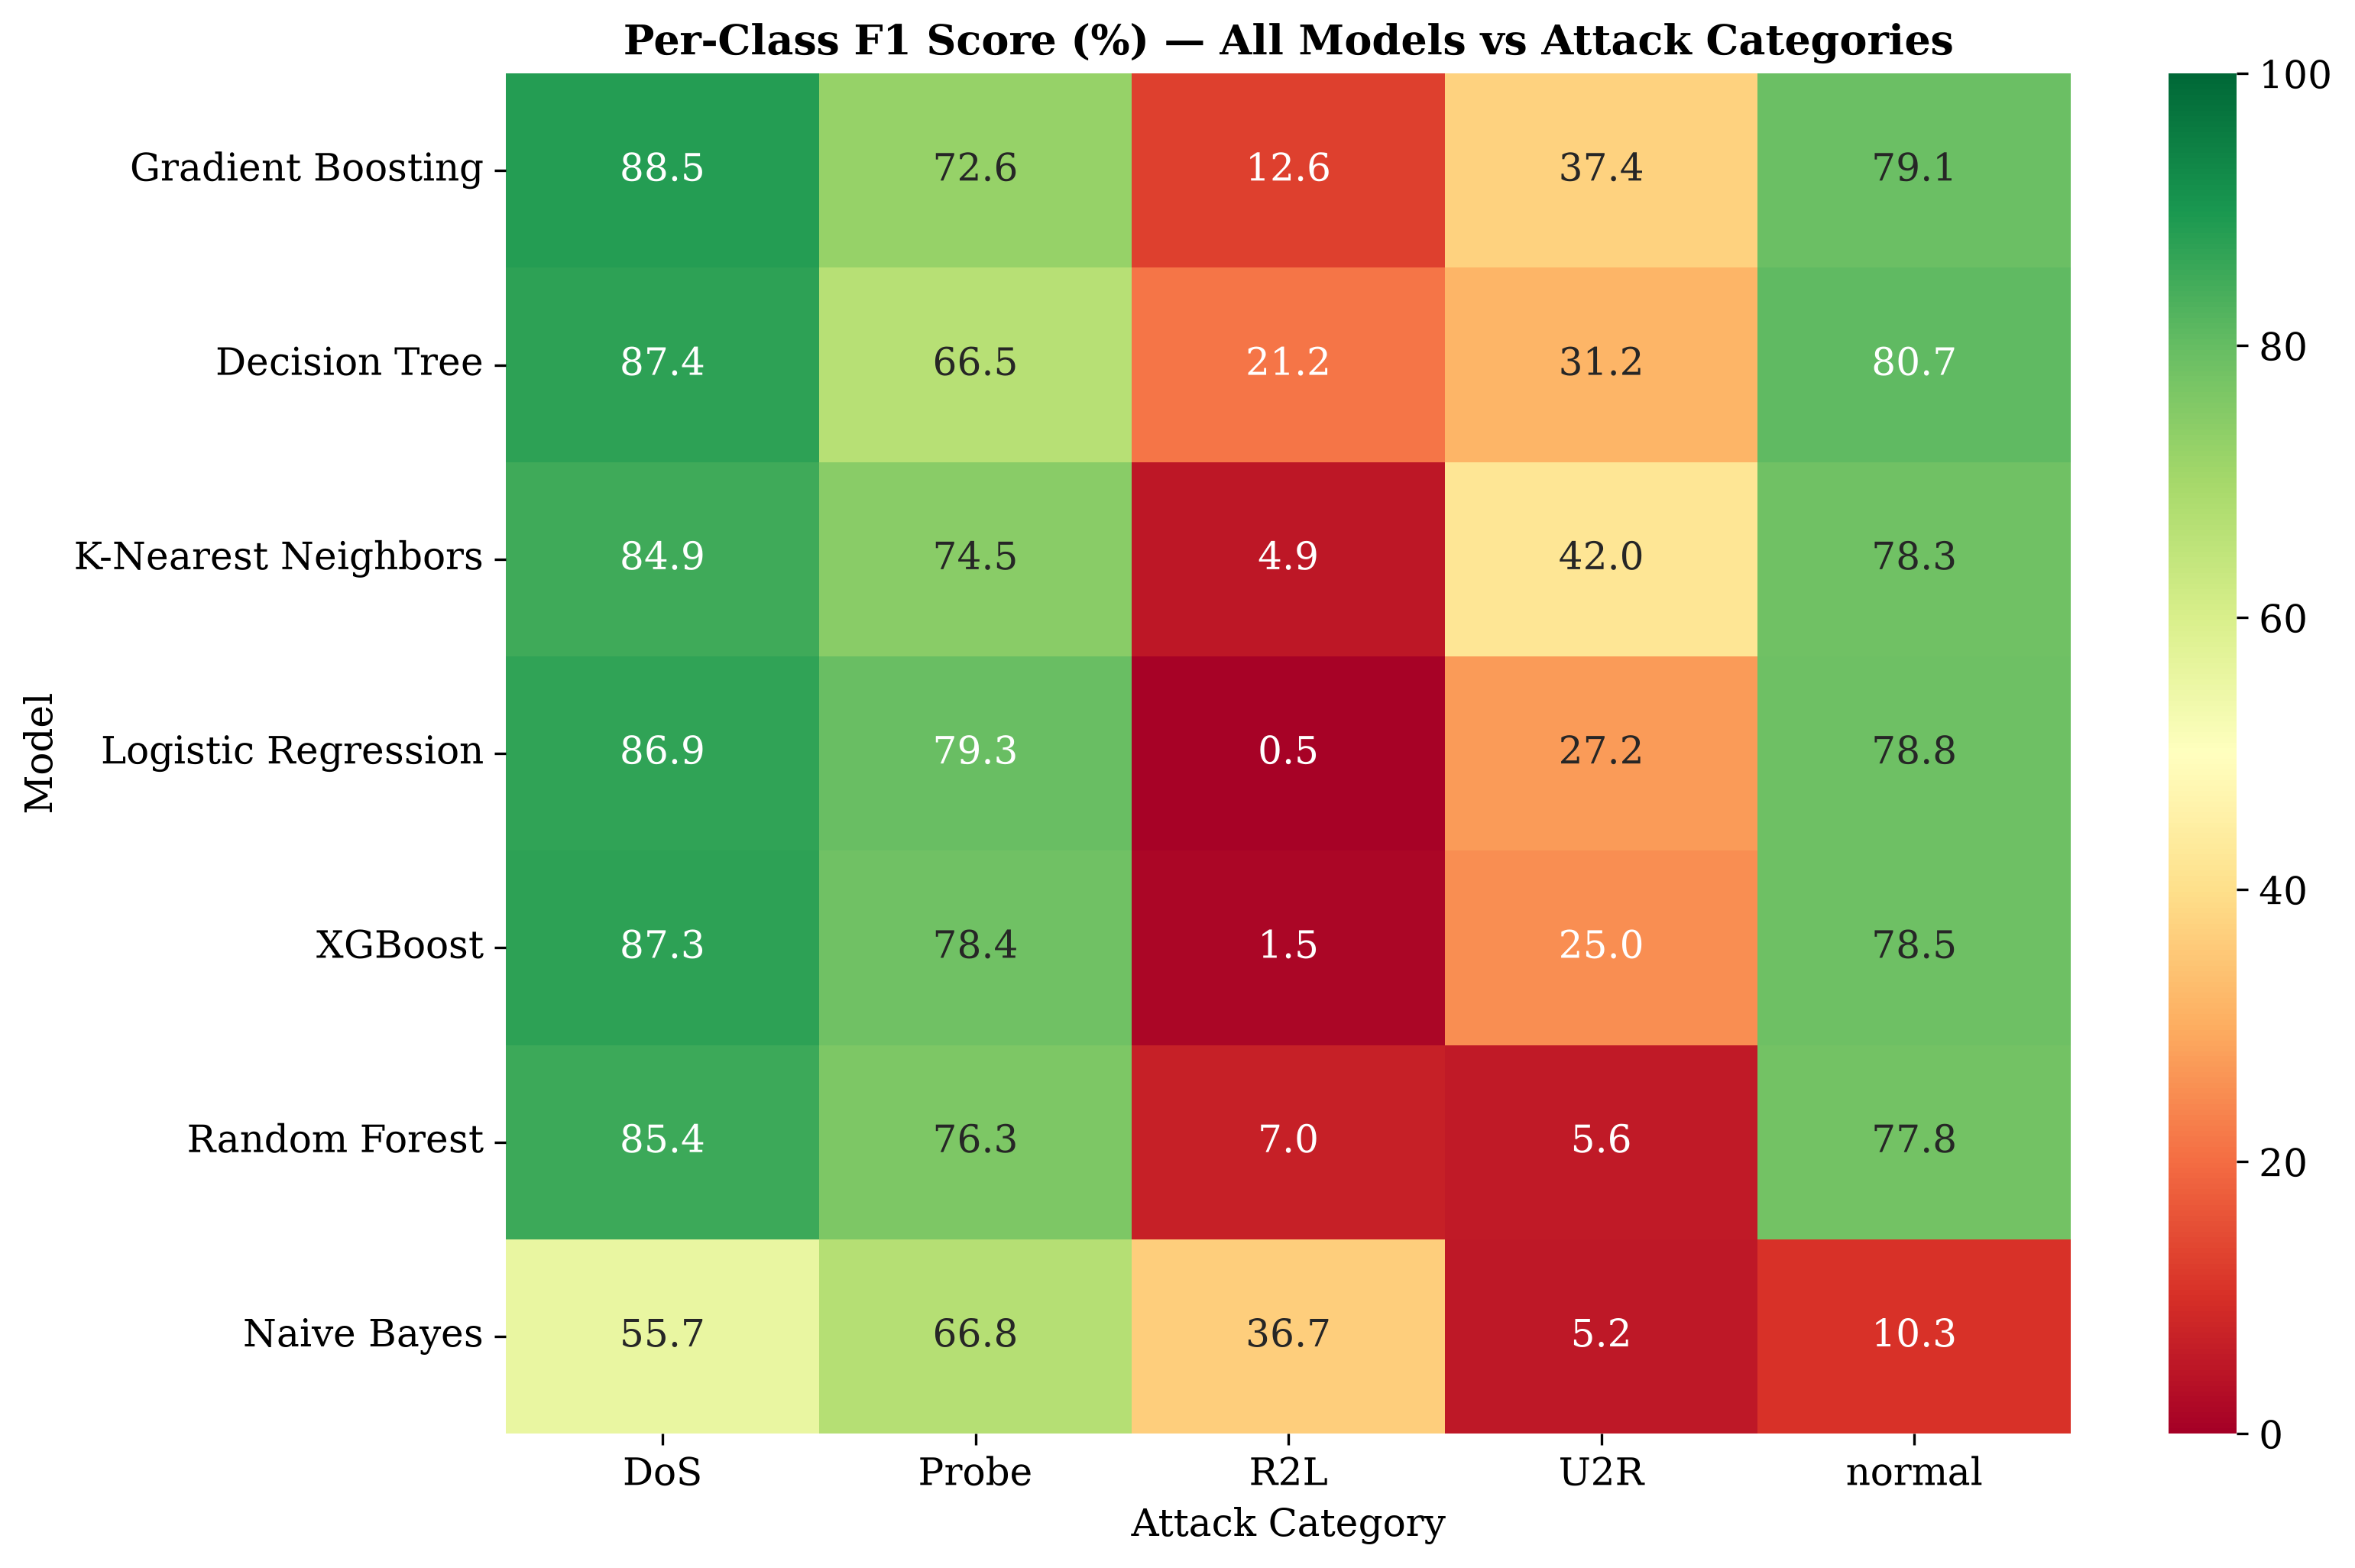

Figure 9 saved


In [ ]:
# CELL 13 — Per-Class F1 Heatmap
f1_cols = [f'F1_{c}' for c in classes]
f1_matrix = mc_df.set_index('Model')[f1_cols].copy()
f1_matrix.columns = classes

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(f1_matrix, annot=True, fmt='.1f', cmap='RdYlGn',
            vmin=0, vmax=100, ax=ax, annot_kws={"size": 12})
ax.set_title('Per-Class F1 Score (%) — All Models vs Attack Categories',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Attack Category', fontsize=12)
ax.set_ylabel('Model', fontsize=12)
plt.tight_layout()
plt.savefig('../figures/fig9_perclass_f1_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 9 saved")

Running 5-fold cross-validation...
  Decision Tree: 99.78% ± 0.02%
  Random Forest: 99.88% ± 0.03%
  Naive Bayes: 88.62% ± 0.35%
  K-Nearest Neighbors: 99.55% ± 0.02%
  Logistic Regression: 94.99% ± 0.25%
  XGBoost: 99.90% ± 0.03%
  Gradient Boosting: 99.56% ± 0.02%


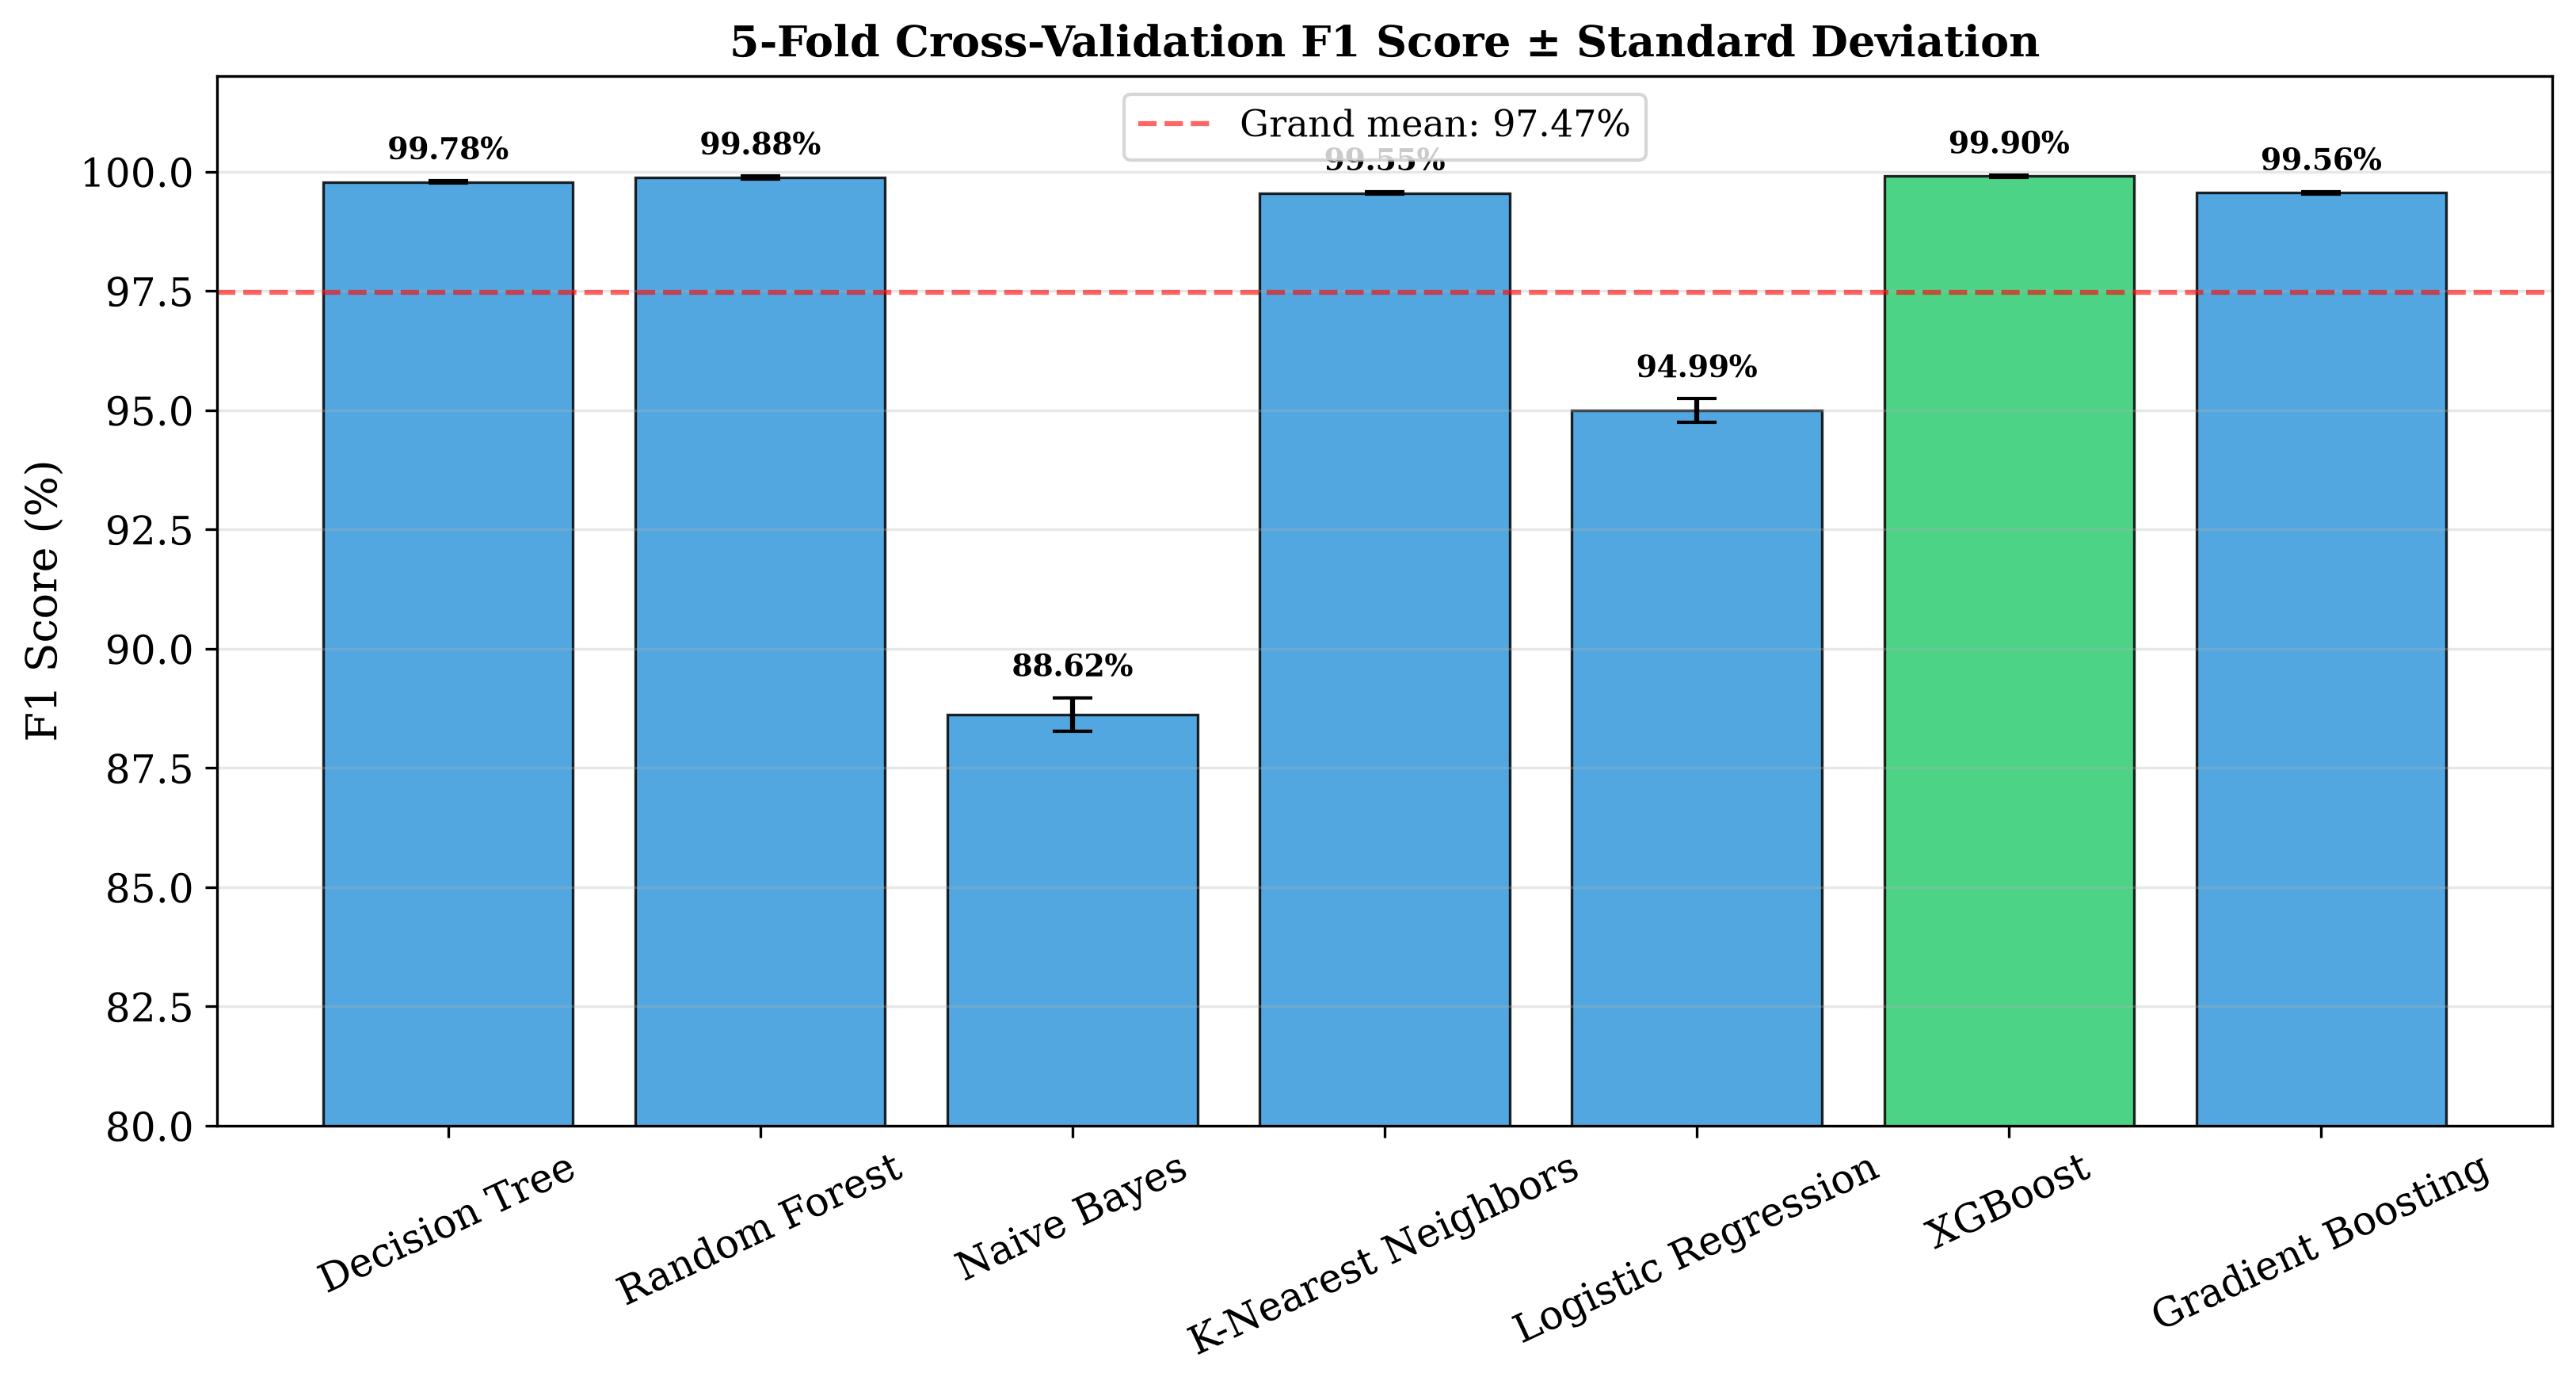


=== STATISTICAL SIGNIFICANCE TESTS (XGBoost vs all others) ===
  XGBoost vs Decision Tree: t=16.470, p=0.0001, significant=YES
  XGBoost vs Random Forest: t=2.252, p=0.0875, significant=NO
  XGBoost vs Naive Bayes: t=66.734, p=0.0000, significant=YES
  XGBoost vs K-Nearest Neighbors: t=18.478, p=0.0001, significant=YES
  XGBoost vs Logistic Regression: t=41.028, p=0.0000, significant=YES
  XGBoost vs Gradient Boosting: t=58.362, p=0.0000, significant=YES


In [ ]:
# CELL 14 — Cross-Validation with Error Bars
from sklearn.model_selection import cross_val_score, StratifiedKFold
from scipy import stats

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}

print("Running 5-fold cross-validation...")
for name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train,
                             cv=cv, scoring='f1', n_jobs=-1)
    cv_scores[name] = scores
    print(f"  {name}: {scores.mean()*100:.2f}% ± {scores.std()*100:.2f}%")

# Figure with error bars
fig, ax = plt.subplots(figsize=(11, 6))
names  = list(cv_scores.keys())
means  = [cv_scores[n].mean()*100 for n in names]
stds   = [cv_scores[n].std()*100 for n in names]
colors = ['#2ecc71' if n == 'XGBoost' else '#3498db' for n in names]

bars = ax.bar(names, means, yerr=stds, capsize=6,
              color=colors, edgecolor='black', linewidth=0.8, alpha=0.85)
ax.set_ylabel('F1 Score (%)', fontsize=13)
ax.set_title('5-Fold Cross-Validation F1 Score ± Standard Deviation',
             fontsize=13, fontweight='bold')
ax.set_ylim(80, 102)
ax.tick_params(axis='x', rotation=25)
for bar, mean, std in zip(bars, means, stds):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+std+0.3,
            f'{mean:.2f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.axhline(y=np.mean(means), color='red', linestyle='--', alpha=0.6,
           label=f'Grand mean: {np.mean(means):.2f}%')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/fig10_cv_error_bars.png', dpi=300, bbox_inches='tight')
plt.show()

# Pairwise t-tests
print("\n=== STATISTICAL SIGNIFICANCE TESTS (XGBoost vs all others) ===")
ttest_rows = []
for name in names:
    if name == 'XGBoost':
        continue
    t, p = stats.ttest_rel(cv_scores['XGBoost'], cv_scores[name])
    sig = "YES" if p < 0.05 else "NO"
    print(f"  XGBoost vs {name}: t={t:.3f}, p={p:.4f}, significant={sig}")
    ttest_rows.append({'Comparison': f'XGBoost vs {name}',
                       't_stat': round(t,4), 'p_value': round(p,4),
                       'Significant_p005': p < 0.05})

pd.DataFrame(ttest_rows).to_csv('../results/statistical_tests.csv', index=False)

Feature ablation study...
  Top  5 features: F1 = 79.58%
  Top 10 features: F1 = 75.61%
  Top 15 features: F1 = 78.71%
  Top 20 features: F1 = 79.31%
  Top 25 features: F1 = 78.50%
  Top 30 features: F1 = 78.21%
  Top 35 features: F1 = 79.57%
  Top 41 features: F1 = 80.06%


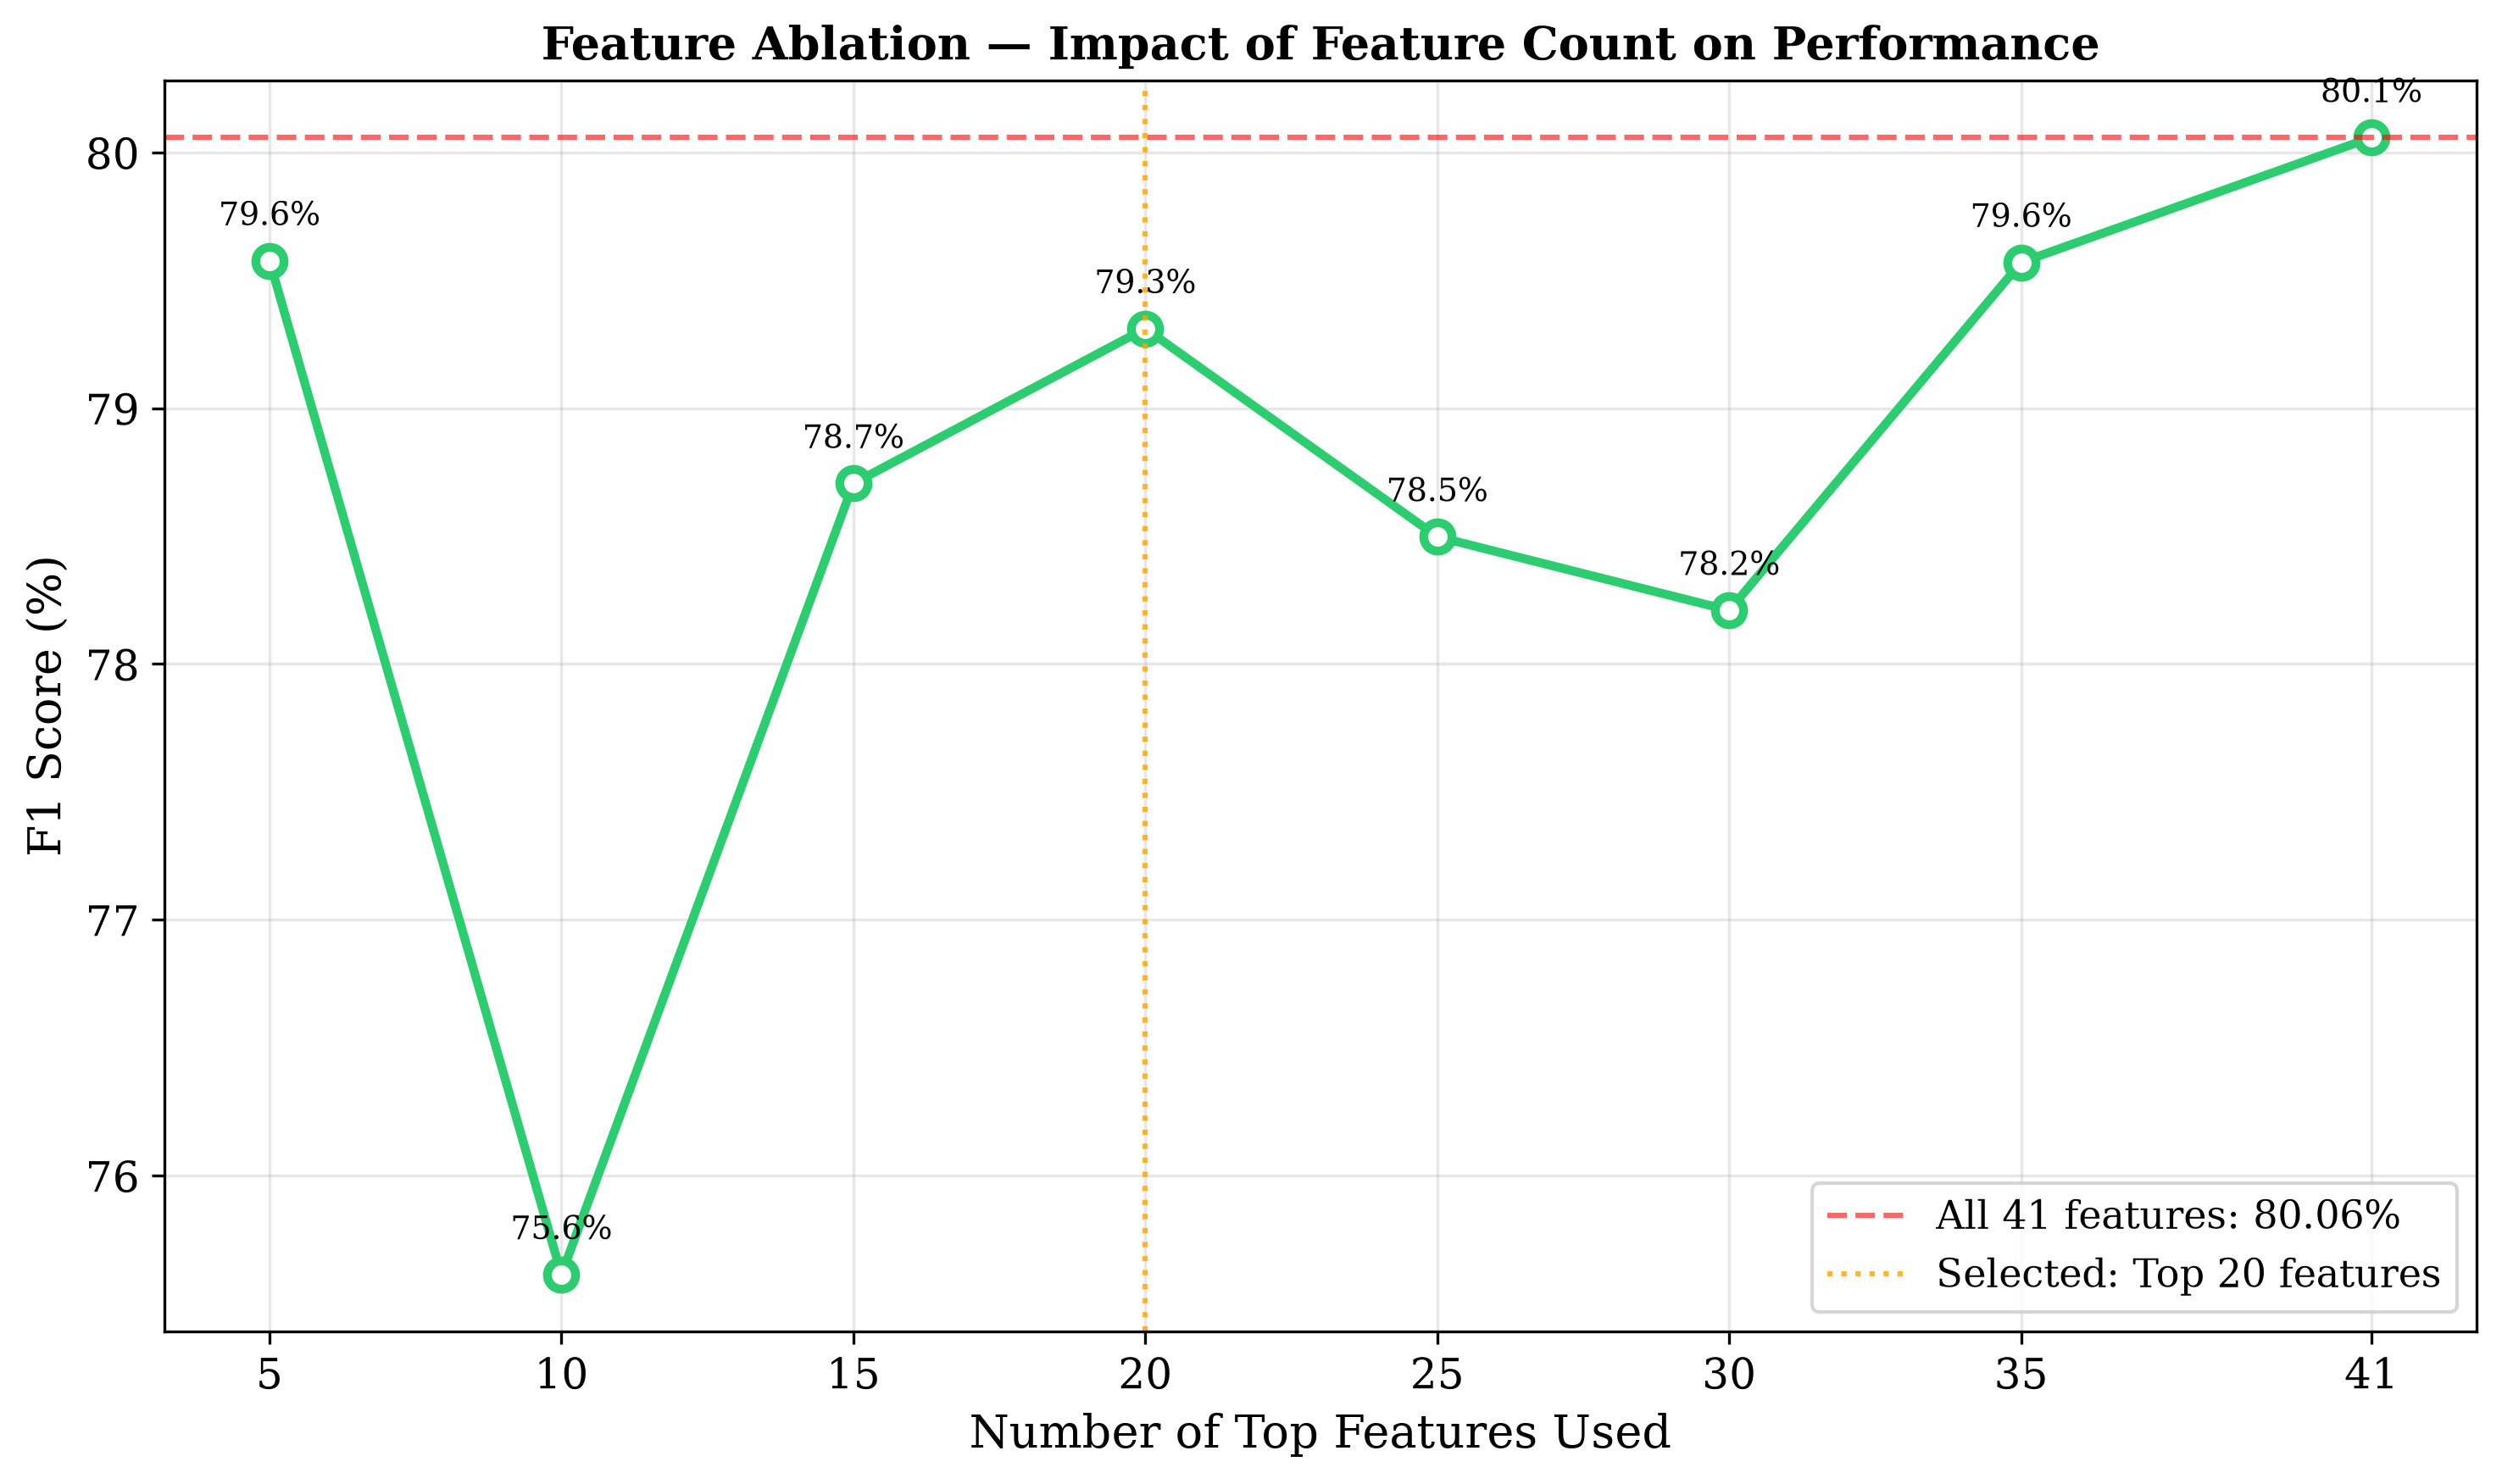

 N_Features  F1_Score
          5 79.577078
         10 75.612879
         15 78.705975
         20 79.311614
         25 78.497661
         30 78.210008
         35 79.570386
         41 80.058490


In [ ]:
# CELL 15 — Feature Ablation Study
from xgboost import XGBClassifier

top_n_values = [5, 10, 15, 20, 25, 30, 35, 41]
f1_scores_ablation = []

print("Feature ablation study...")
for n in top_n_values:
    top_idx = feature_importance_df.nlargest(n, 'RF_Importance').index.tolist()
    X_tr_n  = X_train_scaled[:, top_idx]
    X_te_n  = X_test_scaled[:, top_idx]
    
    model = XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
    model.fit(X_tr_n, y_train)
    y_pred_n = model.predict(X_te_n)
    f1_n = f1_score(y_test, y_pred_n, zero_division=0)
    f1_scores_ablation.append(f1_n * 100)
    print(f"  Top {n:2d} features: F1 = {f1_n*100:.2f}%")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(top_n_values, f1_scores_ablation, 'o-', color='#2ecc71',
        linewidth=2.5, markersize=8, markerfacecolor='white', markeredgewidth=2.5)
ax.axhline(y=f1_scores_ablation[-1], color='red', linestyle='--', alpha=0.6,
           label=f'All 41 features: {f1_scores_ablation[-1]:.2f}%')
ax.axvline(x=20, color='orange', linestyle=':', alpha=0.8,
           label='Selected: Top 20 features')
ax.set_xlabel('Number of Top Features Used', fontsize=13)
ax.set_ylabel('F1 Score (%)', fontsize=13)
ax.set_title('Feature Ablation — Impact of Feature Count on Performance',
             fontsize=13, fontweight='bold')
ax.set_xticks(top_n_values)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
for x, y in zip(top_n_values, f1_scores_ablation):
    ax.annotate(f'{y:.1f}%', (x, y), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('../figures/fig11_feature_ablation.png', dpi=300, bbox_inches='tight')
plt.show()

ablation_df = pd.DataFrame({'N_Features': top_n_values,
                             'F1_Score': f1_scores_ablation})
ablation_df.to_csv('../results/feature_ablation.csv', index=False)
print(ablation_df.to_string(index=False))

In [ ]:
# CELL 16 - Proposed Hybrid Model: Confidence-Gated Ensemble
# ============================================================
# GOAL: Improve detection of the rare attack classes (R2L, U2R) that
# every model above struggles with (see multiclass_results.csv),
# WITHOUT retraining or overwriting any of the models/results above.
#
# IDEA: XGBoost is the strongest overall model but is nearly blind to
# R2L/U2R. Naive Bayes and KNN are weaker overall but noticeably
# better at catching those two rare classes.
#
# Instead of averaging every model together on every sample (plain
# stacking/voting - already widely published for NSL-KDD), this
# routes each test sample INDIVIDUALLY based on how confident XGBoost is:
#   - HIGH confidence  -> trust XGBoost (it's usually right on the
#                         majority classes: DoS, Probe, normal)
#   - LOW confidence    -> fall back to a minority-class specialist
#                         ensemble (Naive Bayes + KNN, averaged),
#                         which historically catches more R2L/U2R cases.
#
# This cell only creates NEW variables (primary_model, nb_specialist,
# knn_specialist, hybrid_pred_final, hybrid_comparison_df, etc.) and
# does not touch models, trained_models, results_df, mc_df, or any
# other variable used by the cells above.
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# --- Step 1: Primary model (majority-class specialist) ---
primary_model = XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
primary_model.fit(X_train_scaled, y_train_mc)
primary_proba = primary_model.predict_proba(X_test_scaled)
primary_pred  = np.argmax(primary_proba, axis=1)
primary_conf  = np.max(primary_proba, axis=1)

# --- Step 2: Minority-class specialist ensemble (NB + KNN averaged) ---
nb_specialist  = GaussianNB()
knn_specialist = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
nb_specialist.fit(X_train_scaled, y_train_mc)
knn_specialist.fit(X_train_scaled, y_train_mc)

nb_proba  = nb_specialist.predict_proba(X_test_scaled)
knn_proba = knn_specialist.predict_proba(X_test_scaled)
specialist_proba = (nb_proba + knn_proba) / 2
specialist_pred  = np.argmax(specialist_proba, axis=1)

# --- Step 3: Sweep confidence thresholds to find the best cutoff ---
print("=== THRESHOLD SWEEP (choosing the best confidence cutoff) ===\n")
threshold_results = []
for THRESH in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]:
    hybrid_pred_t = np.where(primary_conf >= THRESH, primary_pred, specialist_pred)
    n_routed = int(np.sum(primary_conf < THRESH))
    macro_f1_t = f1_score(y_test_mc, hybrid_pred_t, average='macro', zero_division=0)
    acc_t = accuracy_score(y_test_mc, hybrid_pred_t)
    threshold_results.append({
        'Threshold': THRESH, 'Routed_to_Specialist_%': round(n_routed/len(y_test_mc)*100, 2),
        'Accuracy': round(acc_t*100, 2), 'Macro_F1': round(macro_f1_t*100, 2)
    })
    print(f"Threshold={THRESH:.2f}  routed_to_specialist={n_routed} ({n_routed/len(y_test_mc)*100:.2f}%)  "
          f"Accuracy={acc_t*100:.2f}%  Macro_F1={macro_f1_t*100:.2f}%")

threshold_df = pd.DataFrame(threshold_results)
best_threshold = threshold_df.loc[threshold_df['Macro_F1'].idxmax(), 'Threshold']
print(f"\nBest threshold by Macro F1: {best_threshold}")

# --- Step 4: Build the final hybrid prediction using the best threshold ---
hybrid_pred_final = np.where(primary_conf >= best_threshold, primary_pred, specialist_pred)

hybrid_macro_f1 = f1_score(y_test_mc, hybrid_pred_final, average='macro', zero_division=0)
hybrid_weighted_f1 = f1_score(y_test_mc, hybrid_pred_final, average='weighted', zero_division=0)
hybrid_acc = accuracy_score(y_test_mc, hybrid_pred_final)
hybrid_f1_per = f1_score(y_test_mc, hybrid_pred_final, average=None,
                          labels=list(range(len(classes))), zero_division=0)

primary_macro_f1 = f1_score(y_test_mc, primary_pred, average='macro', zero_division=0)
primary_acc = accuracy_score(y_test_mc, primary_pred)
primary_f1_per = f1_score(y_test_mc, primary_pred, average=None,
                           labels=list(range(len(classes))), zero_division=0)

hybrid_comparison_df = pd.DataFrame({
    'Class': classes,
    'XGBoost_Alone_F1': (primary_f1_per * 100).round(2),
    'Proposed_Hybrid_F1': (hybrid_f1_per * 100).round(2),
})
hybrid_comparison_df['Improvement'] = (
    hybrid_comparison_df['Proposed_Hybrid_F1'] - hybrid_comparison_df['XGBoost_Alone_F1']
).round(2)

print(f"\n=== PROPOSED HYBRID vs XGBOOST ALONE (threshold={best_threshold}) ===")
print(f"XGBoost alone -> Accuracy: {primary_acc*100:.2f}%   Macro F1: {primary_macro_f1*100:.2f}%")
print(f"Proposed Hybrid -> Accuracy: {hybrid_acc*100:.2f}%   Macro F1: {hybrid_macro_f1*100:.2f}%")
print(f"Macro F1 improvement: {(hybrid_macro_f1 - primary_macro_f1)*100:+.2f} points\n")
print(hybrid_comparison_df.to_string(index=False))

# --- Step 5: Figure comparing XGBoost alone vs Proposed Hybrid, per class ---
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(classes))
width = 0.35
ax.bar(x - width/2, hybrid_comparison_df['XGBoost_Alone_F1'], width, label='XGBoost Alone', color='#3498db')
ax.bar(x + width/2, hybrid_comparison_df['Proposed_Hybrid_F1'], width, label='Proposed Hybrid', color='#2ecc71')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylabel('F1 Score (%)', fontsize=13)
ax.set_title('Proposed Confidence-Gated Hybrid vs XGBoost Alone (Per-Class F1)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
for i, (xg, hy) in enumerate(zip(hybrid_comparison_df['XGBoost_Alone_F1'], hybrid_comparison_df['Proposed_Hybrid_F1'])):
    ax.text(i - width/2, xg + 1, f'{xg:.1f}', ha='center', fontsize=9)
    ax.text(i + width/2, hy + 1, f'{hy:.1f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('../figures/fig14_hybrid_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 14 saved (new file, does not overwrite any existing figure)")

# --- Step 6: Save results to a NEW csv (does not touch existing result files) ---
threshold_df.to_csv('../results/hybrid_threshold_sweep.csv', index=False)
hybrid_comparison_df.to_csv('../results/proposed_hybrid_results.csv', index=False)
print("\nSaved: ../results/hybrid_threshold_sweep.csv")
print("Saved: ../results/proposed_hybrid_results.csv")


In [ ]:
# CELL 18 - HSR-IDS: Hierarchical Specialist Router (proposed method v2)
# ============================================================
# This is a refined version of the Cell 16 hybrid, with two upgrades:
#   1. The specialist is a SMOTE-balanced XGBoost (not averaged NB+KNN),
#      trained ONLY on {normal, R2L, U2R} so it specializes in exactly
#      the classes the gate struggles with.
#   2. The routing rule has TWO trigger conditions instead of one:
#        (a) the gate confidence is low (it is genuinely unsure), OR
#        (b) the gate predicts "normal" but is not near-certain about it.
#      Condition (b) exists because the diagnostic in Cell 16 showed
#      XGBoost is CONFIDENTLY wrong on R2L 95.9% of the time, calling
#      it "normal" with high confidence - a plain low-confidence gate
#      never catches those. This extra condition specifically targets them.
#
# This cell only creates NEW variables (gate, specialist, hsr_pred, etc.)
# It does not modify models, trained_models, results_df, mc_df, or any
# variable from Cell 16. Existing results/figures are not overwritten -
# this saves to NEW files only (fig15_hsr_ids_comparison.png,
# hsr_ids_results.csv, hsr_shap_r2l_top_features.csv).
# ============================================================

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import shap

# --- Stage 1: The Gate (general model, sees all 5 classes) ---
gate = XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
gate.fit(X_train_scaled, y_train_mc)
gate_proba = gate.predict_proba(X_test_scaled)
gate_pred  = np.argmax(gate_proba, axis=1)
gate_conf  = np.max(gate_proba, axis=1)

normal_idx = list(classes).index('normal')
r2l_idx    = list(classes).index('R2L')
u2r_idx    = list(classes).index('U2R')

# --- Stage 2: The Specialist (SMOTE-balanced, trained on normal+R2L+U2R only) ---
rare_mask_train = np.isin(y_train_mc, [normal_idx, r2l_idx, u2r_idx])
X_rare_train = X_train_scaled[rare_mask_train]
y_rare_train = y_train_mc[rare_mask_train]
print("Specialist training data BEFORE SMOTE:",
      {classes[c]: int((y_rare_train == c).sum()) for c in np.unique(y_rare_train)})

sm = SMOTE(random_state=42, k_neighbors=5)
X_rare_bal, y_rare_bal = sm.fit_resample(X_rare_train, y_rare_train)
print("Specialist training data AFTER SMOTE:",
      {classes[c]: int((y_rare_bal == c).sum()) for c in np.unique(y_rare_bal)})

# XGBoost needs labels re-mapped to a contiguous 0..N-1 range for training
spec_le = LabelEncoder()
y_rare_bal_local = spec_le.fit_transform(y_rare_bal)

specialist = XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
specialist.fit(X_rare_bal, y_rare_bal_local)

specialist_proba_local = specialist.predict_proba(X_test_scaled)
specialist_pred = spec_le.inverse_transform(np.argmax(specialist_proba_local, axis=1))

# --- Routing rule + threshold search ---
def run_hsr(low_conf_thresh, normal_certainty_thresh):
    route_uncertain = gate_conf < low_conf_thresh
    route_suspicious_normal = (gate_pred == normal_idx) & (gate_conf < normal_certainty_thresh)
    route_to_specialist = route_uncertain | route_suspicious_normal
    pred = np.where(route_to_specialist, specialist_pred, gate_pred)
    macro_f1 = f1_score(y_test_mc, pred, average='macro', zero_division=0)
    acc = accuracy_score(y_test_mc, pred)
    pct_routed = route_to_specialist.mean() * 100
    return pred, macro_f1, acc, pct_routed

print("\n=== THRESHOLD SEARCH (choosing gate cutoff + normal-certainty cutoff) ===\n")
search_results = []
for low_conf_thresh in [0.5, 0.6, 0.7, 0.8, 0.9]:
    for normal_certainty_thresh in [0.9, 0.95, 0.99, 0.999, 0.9999]:
        _, mf1, acc, pct = run_hsr(low_conf_thresh, normal_certainty_thresh)
        search_results.append({
            'low_conf_thresh': low_conf_thresh, 'normal_certainty_thresh': normal_certainty_thresh,
            'Macro_F1': round(mf1 * 100, 2), 'Accuracy': round(acc * 100, 2),
            'Routed_%': round(pct, 2)
        })
search_df = pd.DataFrame(search_results)
print(search_df.to_string(index=False))

# Pick the setting with the best Macro F1 among options that route <= 15% of
# traffic (keeps the method lightweight, matching the paper's efficiency claim)
lightweight = search_df[search_df['Routed_%'] <= 15]
best_row = lightweight.loc[lightweight['Macro_F1'].idxmax()]
BEST_LOW_CONF = best_row['low_conf_thresh']
BEST_NORMAL_CERTAINTY = best_row['normal_certainty_thresh']
print(f"\nChosen thresholds: low_conf<{BEST_LOW_CONF}, normal_certainty<{BEST_NORMAL_CERTAINTY} "
      f"(Macro_F1={best_row['Macro_F1']}%, Routed={best_row['Routed_%']}%)")

# --- Final HSR-IDS prediction at the chosen thresholds ---
hsr_pred, hsr_macro_f1, hsr_acc, hsr_pct_routed = run_hsr(BEST_LOW_CONF, BEST_NORMAL_CERTAINTY)
hsr_f1_per = f1_score(y_test_mc, hsr_pred, average=None, labels=list(range(len(classes))), zero_division=0)

gate_macro_f1 = f1_score(y_test_mc, gate_pred, average='macro', zero_division=0)
gate_acc = accuracy_score(y_test_mc, gate_pred)
gate_f1_per = f1_score(y_test_mc, gate_pred, average=None, labels=list(range(len(classes))), zero_division=0)

hsr_comparison_df = pd.DataFrame({
    'Class': classes,
    'Gate_XGBoost_F1': (gate_f1_per * 100).round(2),
    'HSR_IDS_F1': (hsr_f1_per * 100).round(2),
})
hsr_comparison_df['Improvement'] = (hsr_comparison_df['HSR_IDS_F1'] - hsr_comparison_df['Gate_XGBoost_F1']).round(2)

print(f"\n=== HSR-IDS vs GATE (XGBoost) ALONE ===")
print(f"Gate alone -> Accuracy: {gate_acc*100:.2f}%   Macro F1: {gate_macro_f1*100:.2f}%")
print(f"HSR-IDS    -> Accuracy: {hsr_acc*100:.2f}%   Macro F1: {hsr_macro_f1*100:.2f}%   "
      f"(routed {hsr_pct_routed:.2f}% of traffic to specialist)")
print(f"Macro F1 improvement: {(hsr_macro_f1 - gate_macro_f1)*100:+.2f} points\n")
print(hsr_comparison_df.to_string(index=False))

# --- Figure: per-class F1, Gate vs HSR-IDS ---
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(classes))
width = 0.35
ax.bar(x - width/2, hsr_comparison_df['Gate_XGBoost_F1'], width, label='Gate (XGBoost alone)', color='#3498db')
ax.bar(x + width/2, hsr_comparison_df['HSR_IDS_F1'], width, label='HSR-IDS (proposed)', color='#27ae60')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylabel('F1 Score (%)', fontsize=13)
ax.set_title('HSR-IDS vs Gate Alone (Per-Class F1)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
for i, (g, h) in enumerate(zip(hsr_comparison_df['Gate_XGBoost_F1'], hsr_comparison_df['HSR_IDS_F1'])):
    ax.text(i - width/2, g + 1, f'{g:.1f}', ha='center', fontsize=9)
    ax.text(i + width/2, h + 1, f'{h:.1f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('../figures/fig15_hsr_ids_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 15 saved (new file)")

# --- SHAP: which features drive the specialist's R2L detections ---
r2l_pred_mask = (specialist_pred == r2l_idx)
print(f"\nSamples specialist predicted as R2L: {r2l_pred_mask.sum()}")
X_r2l_detected = X_test_scaled[r2l_pred_mask][:200]  # cap for speed

explainer = shap.TreeExplainer(specialist)
shap_values = explainer.shap_values(X_r2l_detected)
r2l_local_idx = list(spec_le.classes_).index(r2l_idx)
if isinstance(shap_values, list):
    sv_r2l = shap_values[r2l_local_idx]
else:
    sv_r2l = shap_values[:, :, r2l_local_idx]

mean_abs_shap = np.abs(sv_r2l).mean(axis=0)
shap_df = pd.DataFrame({'Feature': feature_columns, 'Mean_Abs_SHAP': mean_abs_shap})
shap_df = shap_df.sort_values('Mean_Abs_SHAP', ascending=False).head(10)
print("\nTop 10 features driving R2L detections (SHAP):")
print(shap_df.to_string(index=False))

# --- Save results to NEW files only (does not overwrite existing CSVs) ---
search_df.to_csv('../results/hsr_threshold_search.csv', index=False)
hsr_comparison_df.to_csv('../results/hsr_ids_results.csv', index=False)
shap_df.to_csv('../results/hsr_shap_r2l_top_features.csv', index=False)
print("\nSaved: ../results/hsr_threshold_search.csv")
print("Saved: ../results/hsr_ids_results.csv")
print("Saved: ../results/hsr_shap_r2l_top_features.csv")


In [ ]:
# CELL 19 - Ablation Study: Which Part of HSR-IDS Actually Matters?
# ============================================================
# HSR-IDS (Cell 18) glues two ingredients together:
#   (a) SMOTE - balances the specialist's training data
#   (b) Selective routing - only consults the specialist on uncertain/
#       suspicious-normal cases, instead of on every relevant sample
#
# This cell tests all 4 combinations of "SMOTE on/off" x "Routing on/off"
# to find out which ingredient is actually responsible for the improvement,
# instead of just assuming it.
#
# Requires Cell 18 to have been run first (reuses gate, gate_pred, gate_conf,
# X_train_scaled, X_test_scaled, y_train_mc, y_test_mc, classes, normal_idx,
# r2l_idx, u2r_idx). This cell only creates NEW variables (ablation_df,
# specialist_no_smote, etc.) - it does not modify anything from Cell 18 or
# any earlier cell, and only saves to NEW files (fig16_ablation_2x2.png,
# ablation_2x2_results.csv).
# ============================================================

from imblearn.over_sampling import SMOTE as SMOTE_ablation

# --- Build a specialist, with or without SMOTE ---
def build_specialist_ablation(use_smote):
    rare_mask_train = np.isin(y_train_mc, [normal_idx, r2l_idx, u2r_idx])
    X_rare, y_rare = X_train_scaled[rare_mask_train], y_train_mc[rare_mask_train]
    if use_smote:
        sm = SMOTE_ablation(random_state=42, k_neighbors=5)
        X_rare, y_rare = sm.fit_resample(X_rare, y_rare)
    spec_le_local = LabelEncoder()
    y_local = spec_le_local.fit_transform(y_rare)
    specialist_local = XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
    specialist_local.fit(X_rare, y_local)
    return specialist_local, spec_le_local

specialist_no_smote, le_no_smote = build_specialist_ablation(use_smote=False)
specialist_with_smote, le_with_smote = build_specialist_ablation(use_smote=True)

print("Specialist (no SMOTE) trained on:",
      {classes[c]: int((y_train_mc[np.isin(y_train_mc, [normal_idx, r2l_idx, u2r_idx])] == c).sum())
       for c in [normal_idx, r2l_idx, u2r_idx]})
print("Specialist (with SMOTE) trained on a fully balanced set (see Cell 18 output above)")

# --- Predict with a given specialist, routing ON (selective) or OFF (always consult) ---
def predict_with_routing_ablation(specialist_local, spec_le_local, routing_on,
                                   low_conf_thresh=0.5, normal_certainty_thresh=0.999):
    specialist_proba = specialist_local.predict_proba(X_test_scaled)
    specialist_pred = spec_le_local.inverse_transform(np.argmax(specialist_proba, axis=1))

    if routing_on:
        route_uncertain = gate_conf < low_conf_thresh
        route_suspicious_normal = (gate_pred == normal_idx) & (gate_conf < normal_certainty_thresh)
        route_to_specialist = route_uncertain | route_suspicious_normal
    else:
        # Routing OFF = always consult specialist whenever it's relevant
        # (i.e. whenever the gate's own top guess is normal/R2L/U2R)
        route_to_specialist = np.isin(gate_pred, [normal_idx, r2l_idx, u2r_idx])

    final_pred = np.where(route_to_specialist, specialist_pred, gate_pred)
    pct_routed = route_to_specialist.mean() * 100
    return final_pred, pct_routed

ablation_results = []
ablation_configs = [
    ("A: No SMOTE, Routing OFF (always consult)", specialist_no_smote, le_no_smote, False),
    ("B: No SMOTE, Routing ON (selective)",        specialist_no_smote, le_no_smote, True),
    ("C: SMOTE, Routing OFF (always consult)",     specialist_with_smote, le_with_smote, False),
    ("D: SMOTE, Routing ON (selective) = HSR-IDS", specialist_with_smote, le_with_smote, True),
]

print("\n=== 2x2 ABLATION RESULTS ===\n")
for name, spec, spec_le_local, routing_on in ablation_configs:
    pred, pct_routed = predict_with_routing_ablation(spec, spec_le_local, routing_on)
    macro_f1 = f1_score(y_test_mc, pred, average='macro', zero_division=0)
    acc = accuracy_score(y_test_mc, pred)
    f1_per = f1_score(y_test_mc, pred, average=None, labels=list(range(len(classes))), zero_division=0)
    row = {'Version': name, 'Accuracy': round(acc*100, 2), 'Macro_F1': round(macro_f1*100, 2),
           'Routed_%': round(pct_routed, 2)}
    for i, cls in enumerate(classes):
        row[f'F1_{cls}'] = round(f1_per[i]*100, 2)
    ablation_results.append(row)
    print(f"{name}")
    print(f"  Accuracy={acc*100:.2f}%  Macro_F1={macro_f1*100:.2f}%  Routed={pct_routed:.2f}%")

ablation_df = pd.DataFrame(ablation_results)
print("\n=== FULL 2x2 ABLATION TABLE ===")
print(ablation_df.to_string(index=False))

# --- Interpret: isolate SMOTE's effect vs Routing's effect ---
mf1 = {row['Version'][0]: row['Macro_F1'] for row in ablation_results}  # keyed by 'A','B','C','D'
smote_effect_no_routing = mf1['C'] - mf1['A']
smote_effect_with_routing = mf1['D'] - mf1['B']
routing_effect_no_smote = mf1['B'] - mf1['A']
routing_effect_with_smote = mf1['D'] - mf1['C']

print("\n=== WHICH INGREDIENT ACTUALLY MATTERS? ===")
print(f"Effect of adding SMOTE (without routing):  {smote_effect_no_routing:+.2f} Macro-F1 points (A->C)")
print(f"Effect of adding SMOTE (with routing):      {smote_effect_with_routing:+.2f} Macro-F1 points (B->D)")
print(f"Effect of adding routing (without SMOTE):   {routing_effect_no_smote:+.2f} Macro-F1 points (A->B)")
print(f"Effect of adding routing (with SMOTE):      {routing_effect_with_smote:+.2f} Macro-F1 points (C->D)")
print(f"\nRouted traffic: 'always consult' (A/C) = {ablation_df.loc[ablation_df['Version'].str.startswith('A'), 'Routed_%'].values[0]:.2f}%"
      f"   vs   selective routing (B/D) = {ablation_df.loc[ablation_df['Version'].str.startswith('B'), 'Routed_%'].values[0]:.2f}%")

# --- Figure: Macro-F1 for all 4 versions ---
fig, ax = plt.subplots(figsize=(10, 6))
version_labels = ['A: No SMOTE\nRouting OFF', 'B: No SMOTE\nRouting ON',
                   'C: SMOTE\nRouting OFF', 'D: SMOTE\nRouting ON\n(HSR-IDS)']
macro_f1_values = [row['Macro_F1'] for row in ablation_results]
colors_bar = ['#95a5a6', '#7f8c8d', '#85c1a3', '#27ae60']
bars = ax.bar(version_labels, macro_f1_values, color=colors_bar, edgecolor='black', linewidth=0.8)
ax.axhline(y=gate_macro_f1*100, color='red', linestyle='--', alpha=0.7,
           label=f'Gate alone (no specialist): {gate_macro_f1*100:.2f}%')
for bar, val in zip(bars, macro_f1_values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f'{val:.2f}%', ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel('Macro F1 Score (%)', fontsize=13)
ax.set_title('2x2 Ablation: Isolating the Effect of SMOTE vs Routing', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/fig16_ablation_2x2.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nFigure 16 saved (new file)")

# --- Save results to a NEW csv only ---
ablation_df.to_csv('../results/ablation_2x2_results.csv', index=False)
print("Saved: ../results/ablation_2x2_results.csv")
